# Feature Engineering Notebook

## Objectives

*   Engineer features for Classification, Regression and Cluster models


## Inputs

* inputs/datasets/cleaned/TrainSet.csv
* inputs/datasets/cleaned/TestSet.csv

## Outputs

* generate a list with variables to engineer

## Conclusions



* Feature Engineering Transformers
  **Numerical features:**
- age
- creatinine_phosphokinase
- ejection_fraction
- platelets
- serum_creatinine
- serum_sodium

**Binary features:**
- anaemia
- diabetes
- high_blood_pressure
- sex
- smoking

**Preprocessing:**
- Numerical feature scaling using StandardScaler.`
  


---

# Change working directory

We need to change the working directory from its current folder to its parent folder
* We access the current directory with os.getcwd()

In [1]:
import os
current_dir = os.getcwd()
current_dir

'c:\\python_projects\\Predictive_analysis\\jupyter_notebooks'

We want to make the parent of the current directory the new current directory.
* os.path.dirname() gets the parent directory
* os.chir() defines the new current directory

In [2]:
os.chdir(os.path.dirname(current_dir))
print("You set a new current directory")

You set a new current directory


Confirm the new current directory

In [3]:
current_dir = os.getcwd()
current_dir

'c:\\python_projects\\Predictive_analysis'

---

# Load Cleaned Data

Train Set

In [4]:
from pathlib import Path

print("Current directory:", Path.cwd())

Current directory: c:\python_projects\Predictive_analysis


In [5]:

from pathlib import Path

PROJECT_ROOT = Path(r"C:\python_projects\Predictive_analysis")

# Search for the cleaned training dataset
files = list(PROJECT_ROOT.rglob("TrainSetCleaned.csv"))

if files:
    for file in files:
        print("Found:", file)
else:
    print("TrainSetCleaned.csv was not found.")


Found: C:\python_projects\Predictive_analysis\jupyter_notebooks\outputs\datasets\cleaned\TrainSetCleaned.csv


In [6]:

import pandas as pd
from pathlib import Path

train_set_path = Path(
    r"C:\python_projects\Predictive_analysis\jupyter_notebooks\outputs\datasets\cleaned\TrainSetCleaned.csv")


print("File exists:", train_set_path.is_file())

if train_set_path.is_file():
    TrainSet = pd.read_csv(train_set_path)
    display(TrainSet.head(3))
    print("Dataset shape:", TrainSet.shape)
else:
    print("File not found. Check the folder location.")


File exists: True


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking
0,81.0,0,4540,0,35,0,231000.0,1.18,137,1,1
1,50.0,0,185,0,30,0,266000.0,0.70,141,1,1
2,45.0,0,582,0,35,0,385000.0,1.00,145,1,0


Dataset shape: (239, 11)


In [7]:

import pandas as pd
from pathlib import Path

train_set_path = Path(
    r"C:\python_projects\Predictive_analysis\outputs\datasets\cleaned\TrainSetCleaned.csv"
)

print("File exists:", train_set_path.is_file())

if train_set_path.is_file():
    TrainSet = pd.read_csv(train_set_path)
    display(TrainSet.head(3))
    print("Dataset shape:", TrainSet.shape)
else:
    print("File not found. Check the folder location.")


File exists: False
File not found. Check the folder location.


In [8]:
from pathlib import Path

PROJECT_ROOT = Path(r"C:\python_projects\Predictive_analysis")

# Search for the cleaned training dataset
files = list(PROJECT_ROOT.rglob("TrainSetCleaned.csv"))

if files:
    for file in files:
        print("Found:", file)
else:
    print("TrainSetCleaned.csv was not found.")

Found: C:\python_projects\Predictive_analysis\jupyter_notebooks\outputs\datasets\cleaned\TrainSetCleaned.csv


Test Set

In [9]:

import pandas as pd
from pathlib import Path

test_set_path = Path(
    r"C:\python_projects\Predictive_analysis\jupyter_notebooks\outputs\datasets\cleaned\TestSetCleaned.csv"
)

# Check whether the file exists
print("File exists:", test_set_path.is_file())

# Load test dataset
TestSet = pd.read_csv(test_set_path)

# Display first 3 rows
display(TestSet.head(3))


File exists: True


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking
0,40.000,1,101,0,40,0,226000.0,0.8,141,0,0
1,60.667,1,151,1,40,1,201000.0,1.0,136,0,0
2,45.000,1,981,0,30,0,136000.0,1.1,137,1,0


# Data Exploration

In feature engineering, you are interested to evaluate which potential transformation you could do in your variables
* Take your notes in your separate spreadsheet

In [10]:
!pip install ipywidgets


In [11]:
import sys
import importlib.metadata as md

print("Python:", sys.executable)

for package in ["matplotlib", "ydata-profiling", "numpy"]:
    print(package, md.version(package))

Python: c:\python_projects\Predictive_analysis\venv\Scripts\python.exe
matplotlib 3.10.0
ydata-profiling 4.18.4
numpy 2.1.3


In [12]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(r"C:\python_projects\Predictive_analysis")

train_path = (
    PROJECT_ROOT
    / "outputs"
    / "datasets"
    / "cleaned"
    / "TrainSetCleaned.csv"
)

print("File exists:", train_path.exists())

File exists: False


In [13]:
from pathlib import Path

PROJECT_ROOT = Path(r"C:\python_projects\Predictive_analysis")

for file in PROJECT_ROOT.glob("outputs/**/*.csv"):
    print(file.relative_to(PROJECT_ROOT))

outputs\reports\correlation_analysis.csv
outputs\reports\descriptive_statistics.csv
outputs\reports\missing_values.csv
outputs\datasets\collection\HeartFailureData.csv
outputs\datasets\split\TestSet.csv
outputs\datasets\split\TrainSet.csv
outputs\ml_pipeline\cluster_analysis\v1\clusters_profile.csv
outputs\ml_pipeline\predict_death_event\v1\X_test.csv
outputs\ml_pipeline\predict_death_event\v1\X_train.csv
outputs\ml_pipeline\predict_death_event\v1\y_test.csv
outputs\ml_pipeline\predict_death_event\v1\y_train.csv


In [14]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(r"C:\python_projects\Predictive_analysis")

TRAIN_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "datasets"
    / "split"
    / "TrainSet.csv"
)

TrainSet = pd.read_csv(TRAIN_PATH)

print("Training dataset shape:", TrainSet.shape)
print("Columns:", TrainSet.columns.tolist())

display(TrainSet.head())

Training dataset shape: (239, 12)
Columns: ['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'DEATH_EVENT']


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,DEATH_EVENT
0,50.0,0,582,0,62,1,147000.0,0.8,140,1,1,0
1,75.0,1,246,0,15,0,127000.0,1.2,137,1,0,1
2,50.0,1,168,0,38,1,276000.0,1.1,137,1,0,1
3,65.0,0,395,1,25,0,265000.0,1.2,136,1,1,1
4,40.0,0,244,0,45,1,275000.0,0.9,140,0,0,0


In [15]:
import sys
import matplotlib
import numpy
import ydata_profiling

print("Python:", sys.executable)
print("Matplotlib:", matplotlib.__version__)
print("NumPy:", numpy.__version__)
print("ydata-profiling:", ydata_profiling.__version__)

Python: c:\python_projects\Predictive_analysis\venv\Scripts\python.exe
Matplotlib: 3.11.2
NumPy: 2.1.3
ydata-profiling: 4.18.4


C:\Users\omer\AppData\Local\Temp\ipykernel_9140\502654766.py:4: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  import ydata_profiling


In [16]:

from pathlib import Path
import pandas as pd

# ------------------------------------
# Project directories
# ------------------------------------

PROJECT_ROOT = Path(r"C:\python_projects\Predictive_analysis")

OUTPUT_DIR = PROJECT_ROOT / "outputs"

FIGURES_DIR = OUTPUT_DIR / "figures"
REPORTS_DIR = OUTPUT_DIR / "reports"

# Create directories if they do not exist
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------
# Save correlation analysis
# ------------------------------------

if "corr_comparison" in globals():
    corr_comparison.to_csv(
        REPORTS_DIR / "correlation_analysis.csv",
        index=True
    )
    print("Correlation analysis saved.")

# ------------------------------------
# Save descriptive statistics
# ------------------------------------

TrainSet.describe().T.to_csv(
    REPORTS_DIR / "descriptive_statistics.csv"
)

# ------------------------------------
# Save missing values summary
# ------------------------------------

missing_report = pd.DataFrame({
    "Missing_Count": TrainSet.isnull().sum(),
    "Missing_Percentage": TrainSet.isnull().mean() * 100
})

missing_report.to_csv(
    REPORTS_DIR / "missing_values.csv"
)

print("EDA results saved successfully.")
print("Output directory:", REPORTS_DIR)



EDA results saved successfully.
Output directory: C:\python_projects\Predictive_analysis\outputs\reports


# Correlation and PPS Analysis

* We don’t expect major changes compared to the data cleaning notebook since the only data difference is the removal of “customerID” and “TotalCharges”, so correlation levels and PPS will essentially be the same.

# Feature Engineering

## Custom function

We studied this custom function in the feature-engine lesson. That will help you with the feature engineering process.
* Do not worry if you need help understanding the full code at first, as it is expected you will take some time to absorb the use case.
* At this moment, what matters is to understand the function objective and how you can use it.

In [17]:
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import warnings
from feature_engine import transformation as vt
from feature_engine.outliers import Winsorizer
from feature_engine.encoding import OrdinalEncoder
sns.set(style="whitegrid")
warnings.filterwarnings('ignore')


def FeatureEngineeringAnalysis(df, analysis_type=None):
    """
    - used for quick feature engineering on numerical and categorical variables
    to decide which transformation can better transform the distribution shape
    - Once transformed, use a reporting tool, like ydata-profiling, to evaluate distributions
    """
    check_missing_values(df)
    allowed_types = ['numerical', 'ordinal_encoder', 'outlier_winsorizer']
    check_user_entry_on_analysis_type(analysis_type, allowed_types)
    list_column_transformers = define_list_column_transformers(analysis_type)

    # Loop in each variable and engineer the data according to the analysis type
    df_feat_eng = pd.DataFrame([])
    for column in df.columns:
        # create additional columns (column_method) to apply the methods
        df_feat_eng = pd.concat([df_feat_eng, df[column]], axis=1)
        for method in list_column_transformers:
            df_feat_eng[f"{column}_{method}"] = df[column]

        # Apply transformers in respective column_transformers
        df_feat_eng, list_applied_transformers = apply_transformers(
            analysis_type, df_feat_eng, column)

        # For each variable, assess how the transformations perform
        transformer_evaluation(
            column, list_applied_transformers, analysis_type, df_feat_eng)

    return df_feat_eng


def check_user_entry_on_analysis_type(analysis_type, allowed_types):
    """ Check analysis type """
    if analysis_type is None:
        raise SystemExit(
            f"You should pass analysis_type parameter as one of the following options: {allowed_types}")
    if analysis_type not in allowed_types:
        raise SystemExit(
            f"analysis_type argument should be one of these options: {allowed_types}")


def check_missing_values(df):
    if df.isna().sum().sum() != 0:
        raise SystemExit(
            f"There is a missing value in your dataset. Please handle that before getting into feature engineering.")


def define_list_column_transformers(analysis_type):
    """ Set suffix columns according to analysis_type"""
    if analysis_type == 'numerical':
        list_column_transformers = [
            "log_e", "log_10", "reciprocal", "power", "box_cox", "yeo_johnson"]

    elif analysis_type == 'ordinal_encoder':
        list_column_transformers = ["ordinal_encoder"]

    elif analysis_type == 'outlier_winsorizer':
        list_column_transformers = ['iqr']

    return list_column_transformers


def apply_transformers(analysis_type, df_feat_eng, column):
    for col in df_feat_eng.select_dtypes(include='category').columns:
        df_feat_eng[col] = df_feat_eng[col].astype('object')

    if analysis_type == 'numerical':
        df_feat_eng, list_applied_transformers = FeatEngineering_Numerical(
            df_feat_eng, column)

    elif analysis_type == 'outlier_winsorizer':
        df_feat_eng, list_applied_transformers = FeatEngineering_OutlierWinsorizer(
            df_feat_eng, column)

    elif analysis_type == 'ordinal_encoder':
        df_feat_eng, list_applied_transformers = FeatEngineering_CategoricalEncoder(
            df_feat_eng, column)

    return df_feat_eng, list_applied_transformers


def transformer_evaluation(column, list_applied_transformers, analysis_type, df_feat_eng):
    # For each variable, assess how the transformations perform
    print(f"* Variable Analyzed: {column}")
    print(f"* Applied transformation: {list_applied_transformers} \n")
    for col in [column] + list_applied_transformers:

        if analysis_type != 'ordinal_encoder':
            DiagnosticPlots_Numerical(df_feat_eng, col)

        else:
            if col == column:
                DiagnosticPlots_Categories(df_feat_eng, col)
            else:
                DiagnosticPlots_Numerical(df_feat_eng, col)

        print("\n")


def DiagnosticPlots_Categories(df_feat_eng, col):
    plt.figure(figsize=(4, 3))
    sns.countplot(data=df_feat_eng, x=col, palette=[
                  '#432371'], order=df_feat_eng[col].value_counts().index)
    plt.xticks(rotation=90)
    plt.suptitle(f"{col}", fontsize=30, y=1.05)
    plt.show()
    print("\n")


def DiagnosticPlots_Numerical(df, variable):
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    sns.histplot(data=df, x=variable, kde=True, element="step", ax=axes[0])
    stats.probplot(df[variable], dist="norm", plot=axes[1])
    sns.boxplot(x=df[variable], ax=axes[2])

    axes[0].set_title('Histogram')
    axes[1].set_title('QQ Plot')
    axes[2].set_title('Boxplot')
    fig.suptitle(f"{variable}", fontsize=30, y=1.05)
    plt.tight_layout()
    plt.show()


def FeatEngineering_CategoricalEncoder(df_feat_eng, column):
    list_methods_worked = []
    try:
        encoder = OrdinalEncoder(encoding_method='arbitrary', variables=[
                                 f"{column}_ordinal_encoder"])
        df_feat_eng = encoder.fit_transform(df_feat_eng)
        list_methods_worked.append(f"{column}_ordinal_encoder")

    except Exception:
        df_feat_eng.drop([f"{column}_ordinal_encoder"], axis=1, inplace=True)

    return df_feat_eng, list_methods_worked


def FeatEngineering_OutlierWinsorizer(df_feat_eng, column):
    list_methods_worked = []

    # Winsorizer iqr
    try:
        disc = Winsorizer(
            capping_method='iqr', tail='both', fold=1.5, variables=[f"{column}_iqr"])
        df_feat_eng = disc.fit_transform(df_feat_eng)
        list_methods_worked.append(f"{column}_iqr")
    except Exception:
        df_feat_eng.drop([f"{column}_iqr"], axis=1, inplace=True)

    return df_feat_eng, list_methods_worked


def FeatEngineering_Numerical(df_feat_eng, column):
    list_methods_worked = []

    # LogTransformer base e
    try:
        lt = vt.LogTransformer(variables=[f"{column}_log_e"])
        df_feat_eng = lt.fit_transform(df_feat_eng)
        list_methods_worked.append(f"{column}_log_e")
    except Exception:
        df_feat_eng.drop([f"{column}_log_e"], axis=1, inplace=True)

    # LogTransformer base 10
    try:
        lt = vt.LogTransformer(variables=[f"{column}_log_10"], base='10')
        df_feat_eng = lt.fit_transform(df_feat_eng)
        list_methods_worked.append(f"{column}_log_10")
    except Exception:
        df_feat_eng.drop([f"{column}_log_10"], axis=1, inplace=True)

    # ReciprocalTransformer
    try:
        rt = vt.ReciprocalTransformer(variables=[f"{column}_reciprocal"])
        df_feat_eng = rt.fit_transform(df_feat_eng)
        list_methods_worked.append(f"{column}_reciprocal")
    except Exception:
        df_feat_eng.drop([f"{column}_reciprocal"], axis=1, inplace=True)

    # PowerTransformer
    try:
        pt = vt.PowerTransformer(variables=[f"{column}_power"])
        df_feat_eng = pt.fit_transform(df_feat_eng)
        list_methods_worked.append(f"{column}_power")
    except Exception:
        df_feat_eng.drop([f"{column}_power"], axis=1, inplace=True)

    # BoxCoxTransformer
    try:
        bct = vt.BoxCoxTransformer(variables=[f"{column}_box_cox"])
        df_feat_eng = bct.fit_transform(df_feat_eng)
        list_methods_worked.append(f"{column}_box_cox")
    except Exception:
        df_feat_eng.drop([f"{column}_box_cox"], axis=1, inplace=True)

    # YeoJohnsonTransformer
    try:
        yjt = vt.YeoJohnsonTransformer(variables=[f"{column}_yeo_johnson"])
        df_feat_eng = yjt.fit_transform(df_feat_eng)
        list_methods_worked.append(f"{column}_yeo_johnson")
    except Exception:
        df_feat_eng.drop([f"{column}_yeo_johnson"], axis=1, inplace=True)

    return df_feat_eng, list_methods_worked


## Feature Engineering Spreadsheet Summary

* Consider the notes taken in your spreadsheet summary. List the transformers you will use
    * Categorical Encoding
    * Numerical Transformation
    * Smart Correlation Selection

## Dealing with Feature Engineering

### Categorical Encoding - Ordinal: replaces categories with ordinal numbers 

* Step 1: Select variable(s)

In [18]:

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer

# Separate predictors and target

X_train = TrainSet.drop(
    columns=["DEATH_EVENT", "time"],
    errors="ignore"
)

y_train = TrainSet["DEATH_EVENT"]

# Define feature groups
log_features = ["creatinine_phosphokinase"]

numerical_features = [
    "age",
    "ejection_fraction",
    "platelets",
    "serum_creatinine",
    "serum_sodium"
]

binary_features = [
    "anaemia",
    "diabetes",
    "high_blood_pressure",
    "sex",
    "smoking"
]

# Pipeline for skewed features
log_pipeline = Pipeline([
    ("log_transform", FunctionTransformer(
        np.log1p,
        feature_names_out="one-to-one"
    )),
    ("scaler", StandardScaler())
])

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("log", log_pipeline, log_features),
        ("num", StandardScaler(), numerical_features),
        ("binary", "passthrough", binary_features)
    ],
    verbose_feature_names_out=False
)

# Fit transformations on training data only
X_train_transformed = preprocessor.fit_transform(X_train)

# Convert to DataFrame
X_train_fe = pd.DataFrame(
    X_train_transformed,
    columns=preprocessor.get_feature_names_out(),
    index=X_train.index
)

display(X_train_fe.head())
print("Transformed shape:", X_train_fe.shape)


,creatinine_phosphokinase,age,ejection_fraction,platelets,serum_creatinine,serum_sodium,anaemia,diabetes,high_blood_pressure,sex,smoking
0,0.618648,-0.877074,2.060707,-1.144202,-0.555512,0.762947,0.0,0.0,1.0,1.0,1.0
1,-0.140034,1.269505,-1.945510,-1.339078,-0.196972,0.109383,1.0,0.0,0.0,1.0,0.0
2,-0.475283,-0.877074,0.014979,0.112745,-0.286607,0.109383,1.0,0.0,1.0,1.0,0.0
3,0.276964,0.410873,-1.093123,0.005563,-0.196972,-0.108472,0.0,1.0,0.0,1.0,1.0
4,-0.147216,-1.735705,0.611650,0.103001,-0.465877,0.762947,0.0,0.0,1.0,0.0,0.0


Transformed shape: (239, 11)


* Step 2: Create a separate DataFrame, with your variable(s)
Define variables_engineering
For heart failure dataset, it could initially select these continuous clinical features:

In [19]:

variables_engineering = [
    "age",
    "creatinine_phosphokinase",
    "ejection_fraction",
    "platelets",
    "serum_creatinine",
    "serum_sodium"
]

# Check that all columns exist
missing_columns = [
    col for col in variables_engineering
    if col not in TrainSet.columns
]

if missing_columns:
    raise ValueError(f"Columns not found: {missing_columns}")

# Create feature engineering DataFrame
df_engineering = TrainSet[variables_engineering].copy()

display(df_engineering.head(3))
print("Shape:", df_engineering.shape)


,age,creatinine_phosphokinase,ejection_fraction,platelets,serum_creatinine,serum_sodium
0,50.0,582,62,147000.0,0.8,140
1,75.0,246,15,127000.0,1.2,137
2,50.0,168,38,276000.0,1.1,137


Shape: (239, 6)


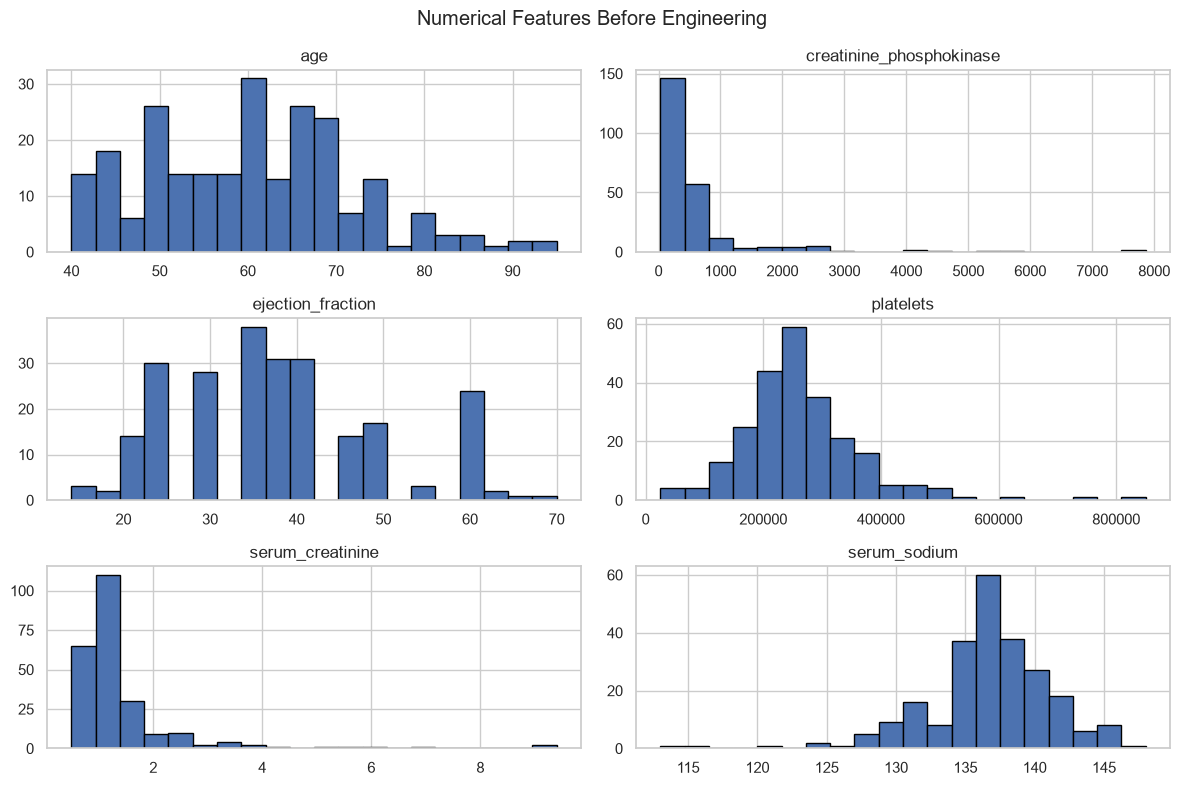

In [20]:

import matplotlib.pyplot as plt
import seaborn as sns

df_engineering.hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Numerical Features Before Engineering")
plt.tight_layout()
plt.show()


In [21]:
import numpy as np

df_engineering["creatinine_phosphokinase_log"] = np.log1p(
    df_engineering["creatinine_phosphokinase"]
)

* Step 3: Create engineered variables(s) by applying the transformation(s), assess engineered variables distribution and select the most suitable method for each variable.

* Variable Analyzed: age
* Applied transformation: [] 



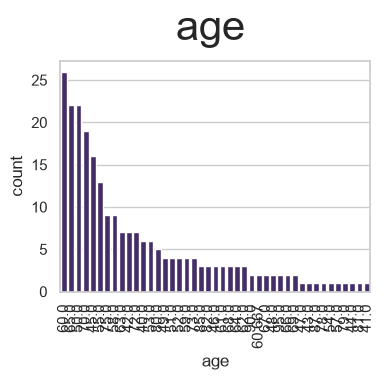





* Variable Analyzed: creatinine_phosphokinase
* Applied transformation: [] 



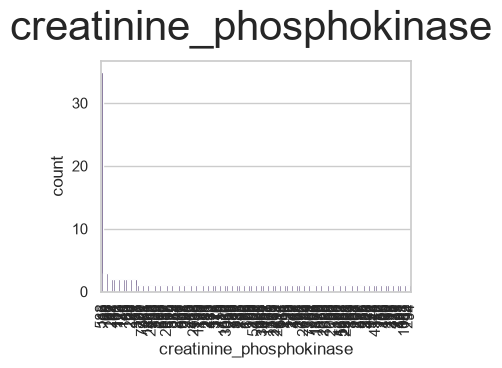





* Variable Analyzed: ejection_fraction
* Applied transformation: [] 



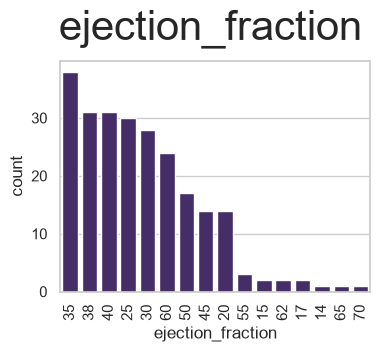





* Variable Analyzed: platelets
* Applied transformation: [] 



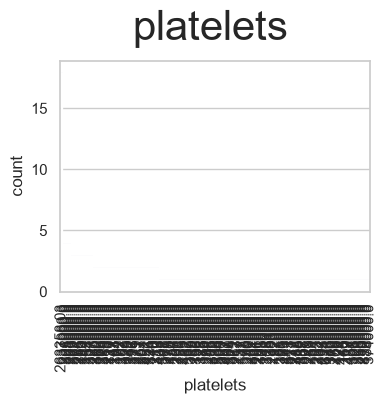





* Variable Analyzed: serum_creatinine
* Applied transformation: [] 



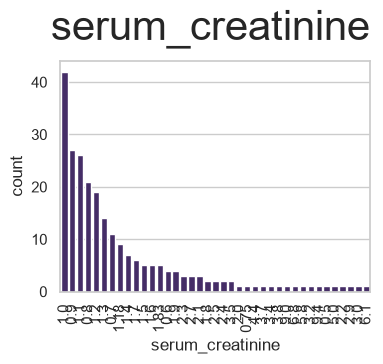





* Variable Analyzed: serum_sodium
* Applied transformation: [] 



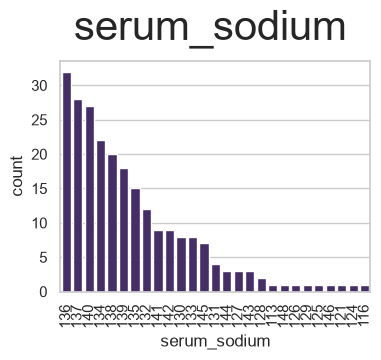





* Variable Analyzed: creatinine_phosphokinase_log
* Applied transformation: [] 



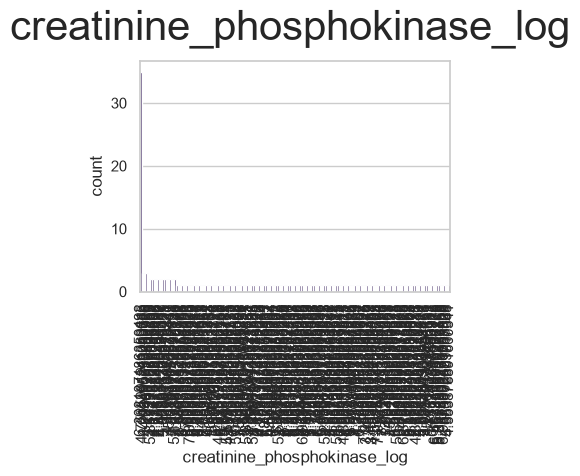

In [22]:
df_engineering = FeatureEngineeringAnalysis(df=df_engineering, analysis_type='ordinal_encoder')

* For each variable, write your conclusion on how the transformation(s) look(s) to be effective.
  * For all variables, the transformation is effective, since it converted categories to numbers.



* Step 4 - Apply the selected transformation to the Train and Test set

### Numerical Transformation

* Step 1: Select variable(s)

In [23]:
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path(r"C:\python_projects\Predictive_analysis")

TrainSet = pd.read_csv(
    PROJECT_ROOT / "outputs" / "datasets" / "split" / "TrainSet.csv"
)

TestSet = pd.read_csv(
    PROJECT_ROOT / "outputs" / "datasets" / "split" / "TestSet.csv"
)

print("Training dataset:", TrainSet.shape)
print("Test dataset:", TestSet.shape)

display(TrainSet.head())
display(TestSet.head())

Training dataset: (239, 12)
Test dataset: (60, 12)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,DEATH_EVENT
0,50.0,0,582,0,62,1,147000.0,0.8,140,1,1,0
1,75.0,1,246,0,15,0,127000.0,1.2,137,1,0,1
2,50.0,1,168,0,38,1,276000.0,1.1,137,1,0,1
3,65.0,0,395,1,25,0,265000.0,1.2,136,1,1,1
4,40.0,0,244,0,45,1,275000.0,0.9,140,0,0,0


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,DEATH_EVENT
0,45.0,0,582,0,80,0,263358.03,1.18,137,0,0,0
1,70.0,0,571,1,45,1,185000.00,1.20,139,1,1,1
2,55.0,0,1820,0,38,0,270000.00,1.20,139,0,0,0
3,75.0,0,99,0,38,1,224000.00,2.50,134,1,0,1
4,65.0,0,892,1,35,0,263358.03,1.10,142,0,0,0


In [24]:
variables_engineering = ['time', 'DEATH_EVENT']
variables_engineering

['time', 'DEATH_EVENT']

* Step 2: Create a separate DataFrame, with your variable(s)

In [25]:
variables_engineering = [
    "age",
    "creatinine_phosphokinase",
    "ejection_fraction",
    "platelets",
    "serum_creatinine",
    "serum_sodium",
    "anaemia",
    "diabetes",
    "high_blood_pressure",
    "sex",
    "smoking"
]

In [26]:
df_engineering = TrainSet[variables_engineering].copy()

display(df_engineering.head(3))
print(df_engineering.dtypes)

,age,creatinine_phosphokinase,ejection_fraction,platelets,serum_creatinine,serum_sodium,anaemia,diabetes,high_blood_pressure,sex,smoking
0,50.0,582,62,147000.0,0.8,140,0,0,1,1,1
1,75.0,246,15,127000.0,1.2,137,1,0,0,1,0
2,50.0,168,38,276000.0,1.1,137,1,0,1,1,0


age                         float64
creatinine_phosphokinase      int64
ejection_fraction             int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
anaemia                       int64
diabetes                      int64
high_blood_pressure           int64
sex                           int64
smoking                       int64
dtype: object


In [27]:
df_engineering = TrainSet[variables_engineering].copy()
df_engineering.head(3)

,age,creatinine_phosphokinase,ejection_fraction,platelets,serum_creatinine,serum_sodium,anaemia,diabetes,high_blood_pressure,sex,smoking
0,50.0,582,62,147000.0,0.8,140,0,0,1,1,1
1,75.0,246,15,127000.0,1.2,137,1,0,0,1,0
2,50.0,168,38,276000.0,1.1,137,1,0,1,1,0


* Step 3: Create engineered variables(s) by applying the transformation(s), assess engineered variables distribution and select the most suitable method

* Variable Analyzed: age
* Applied transformation: ['age_log_e', 'age_log_10', 'age_reciprocal', 'age_power', 'age_box_cox', 'age_yeo_johnson'] 



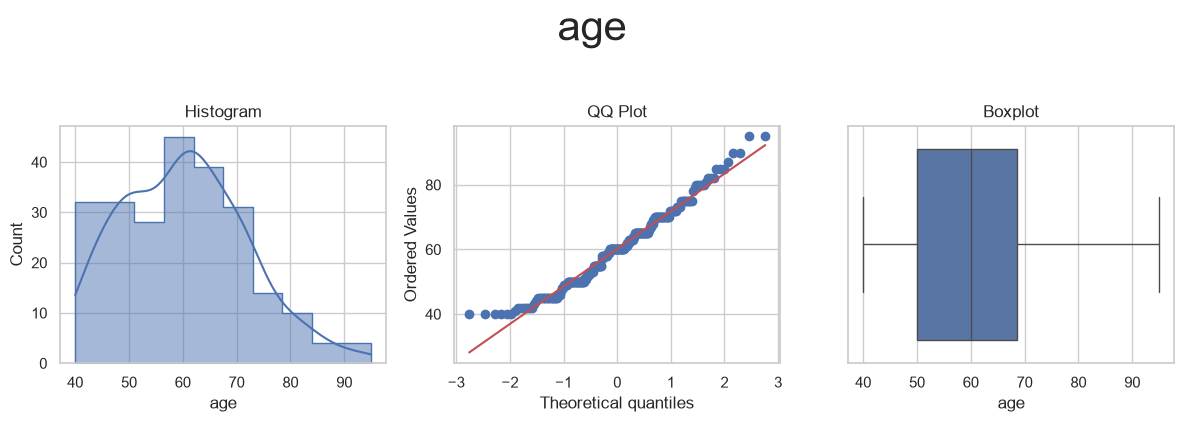

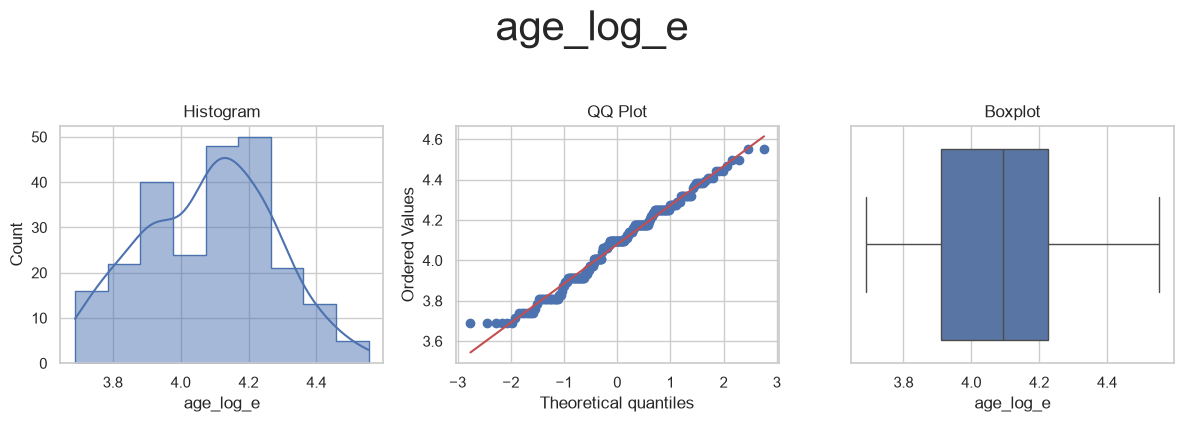

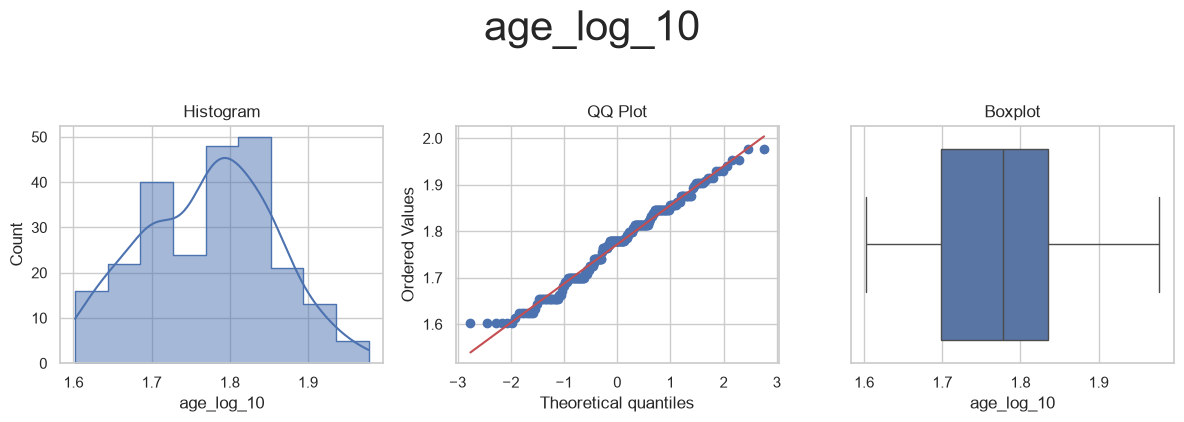

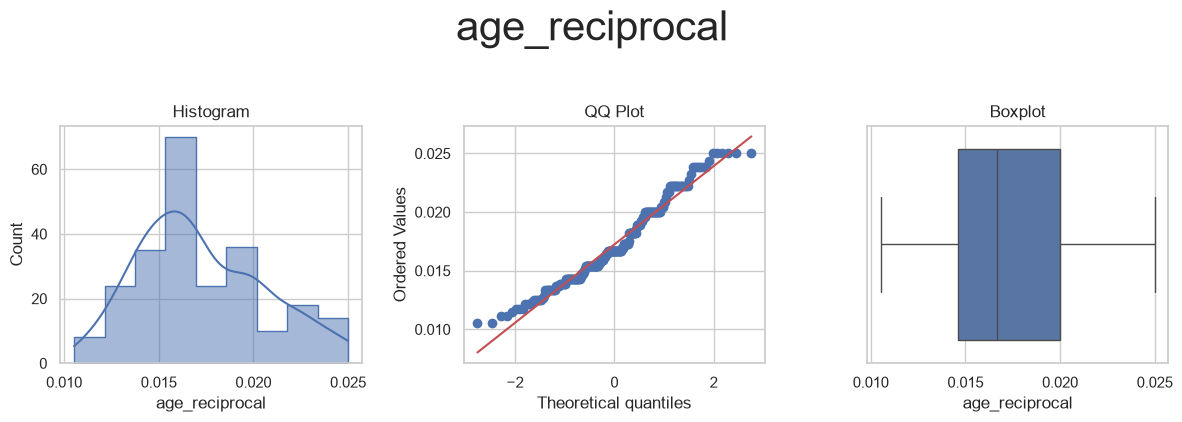

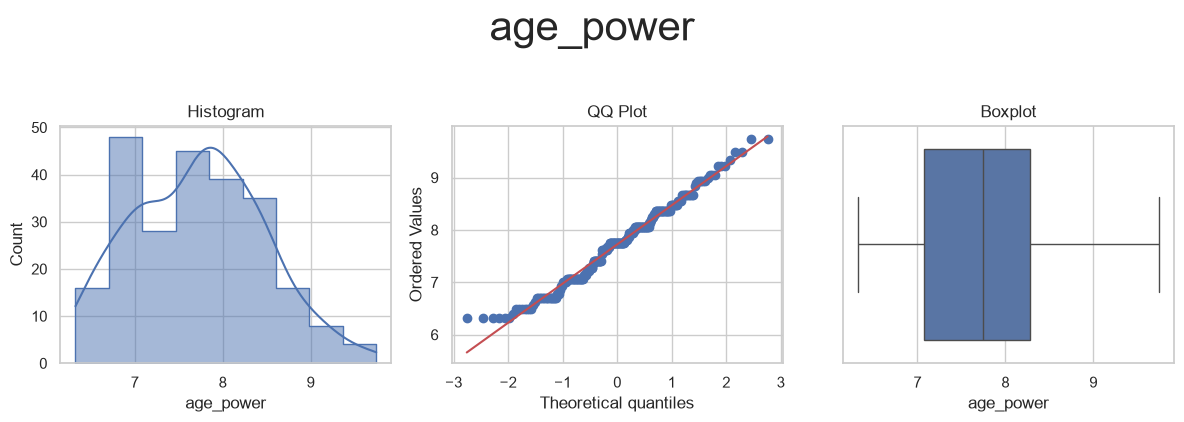

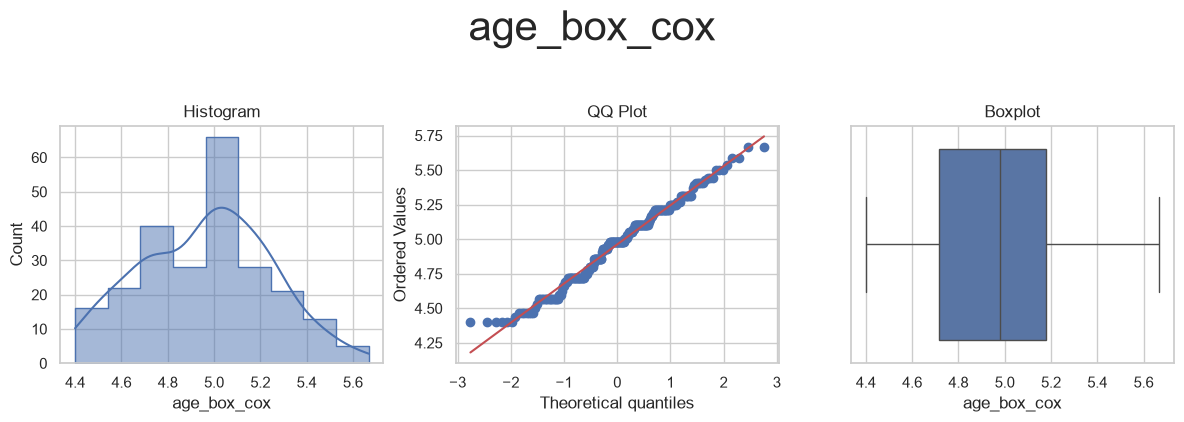

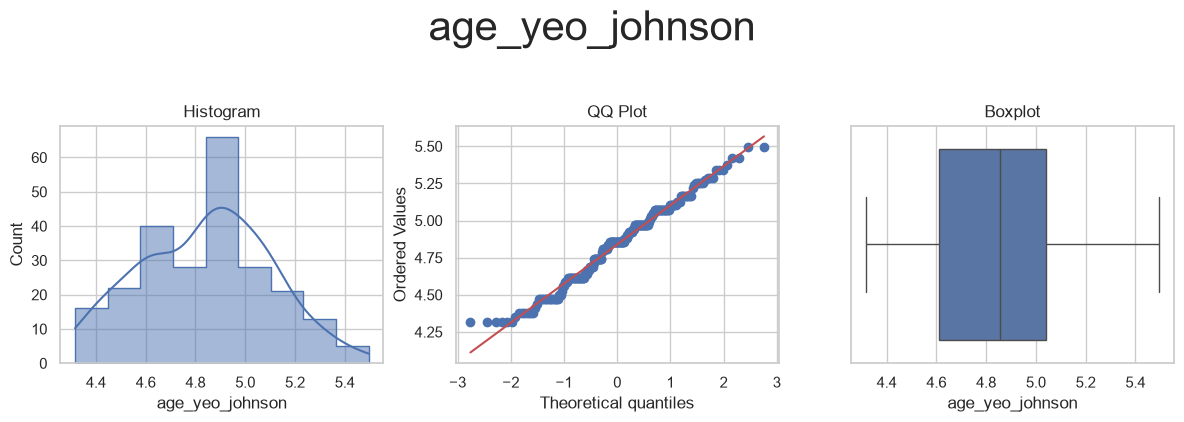



* Variable Analyzed: creatinine_phosphokinase
* Applied transformation: ['creatinine_phosphokinase_log_e', 'creatinine_phosphokinase_log_10', 'creatinine_phosphokinase_reciprocal', 'creatinine_phosphokinase_power', 'creatinine_phosphokinase_box_cox', 'creatinine_phosphokinase_yeo_johnson'] 



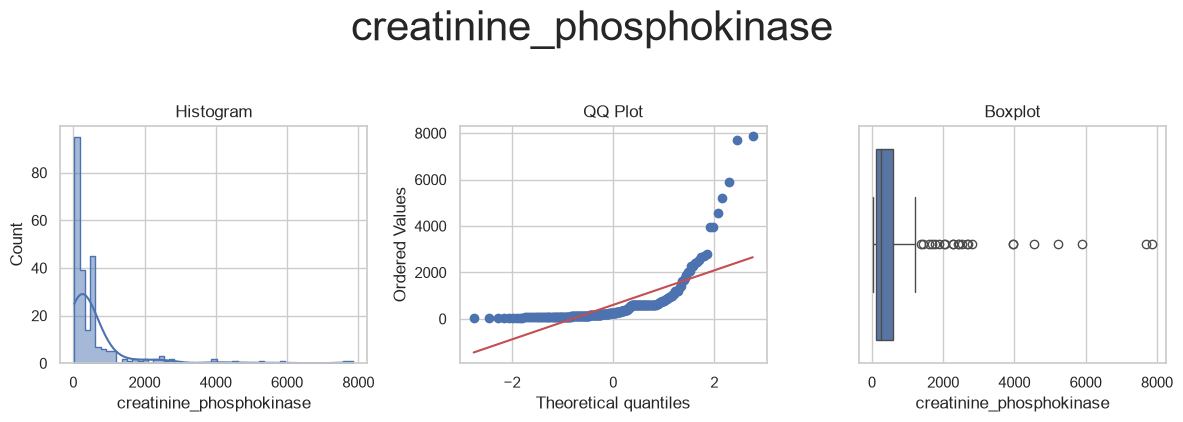

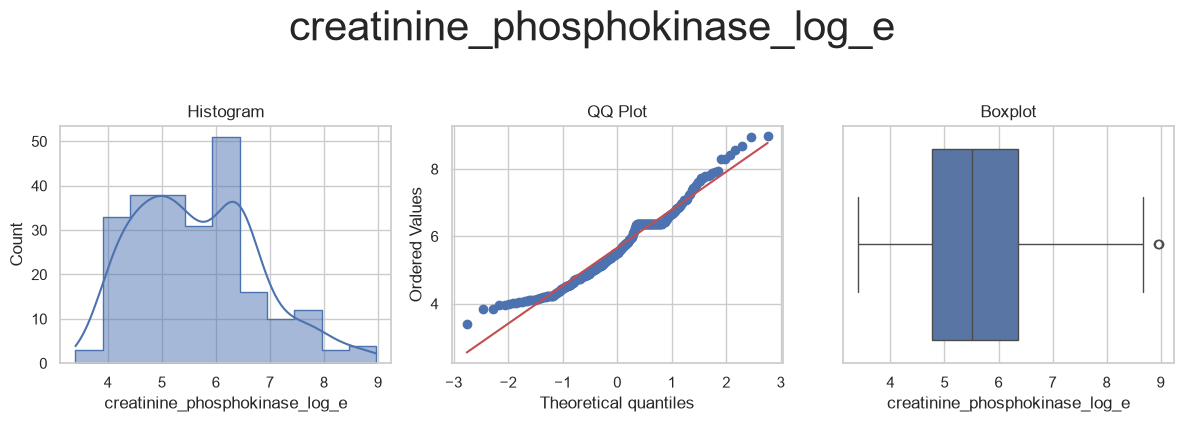

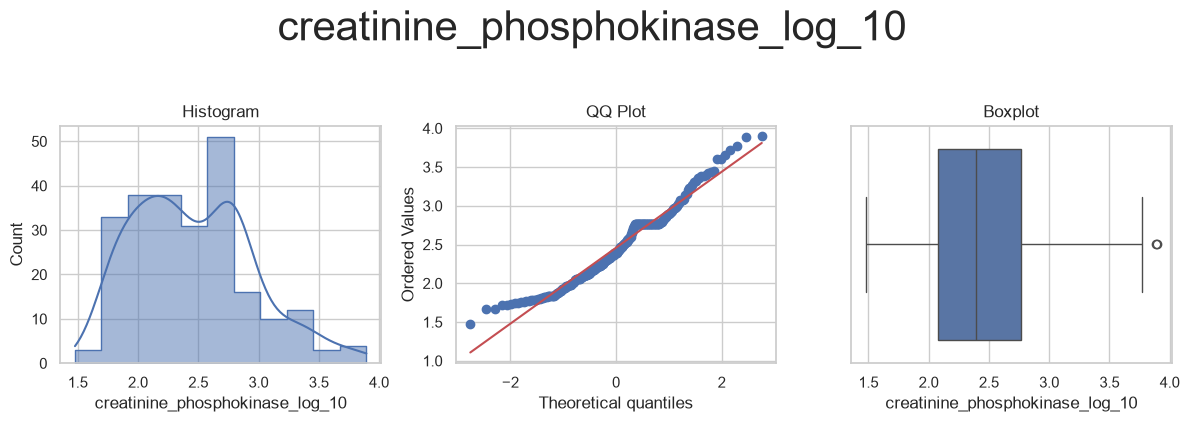

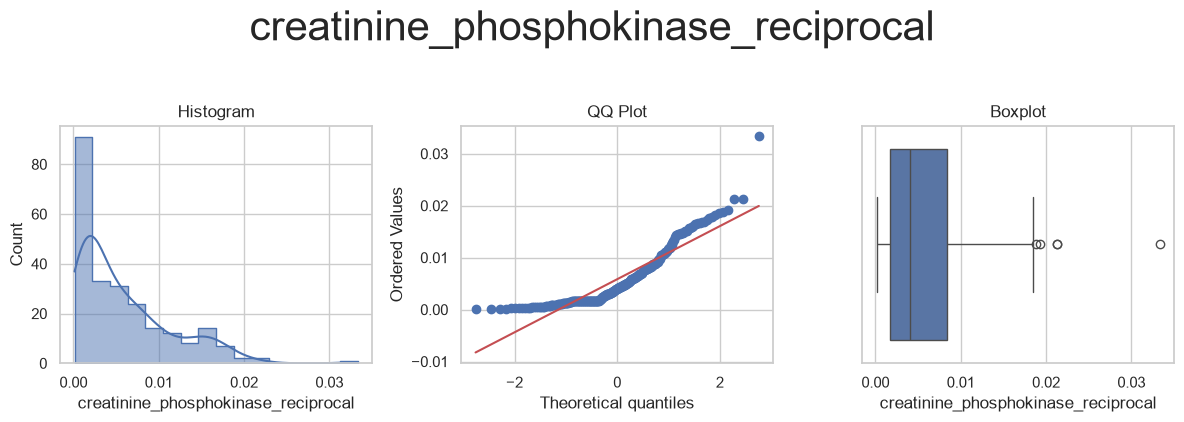

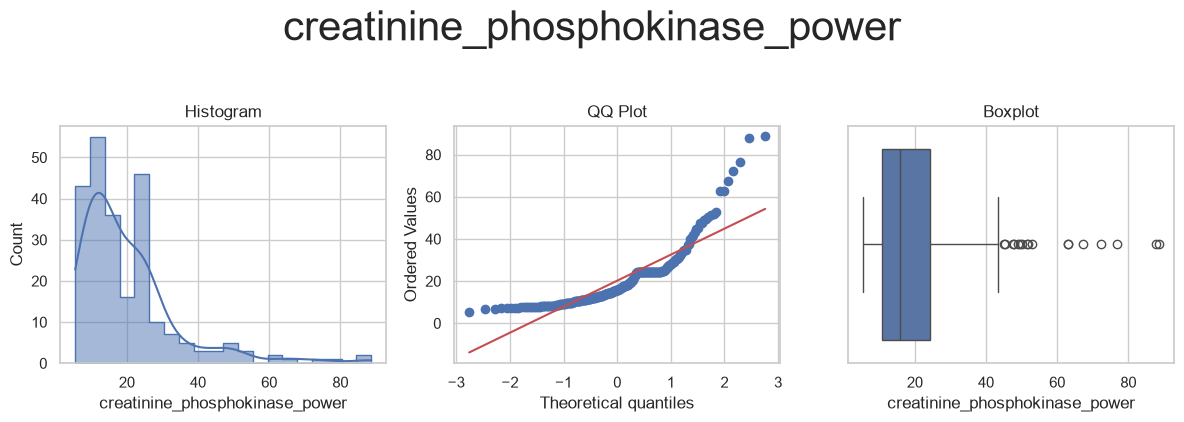

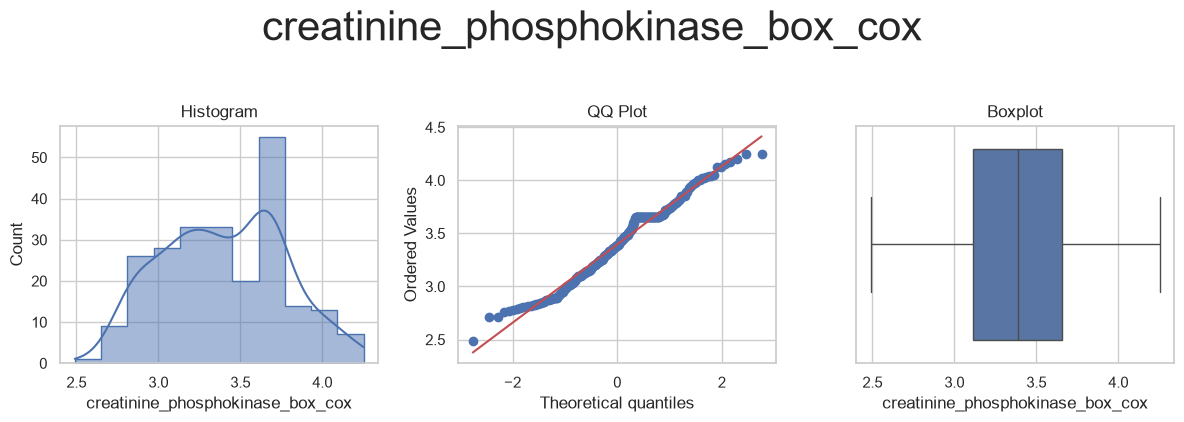

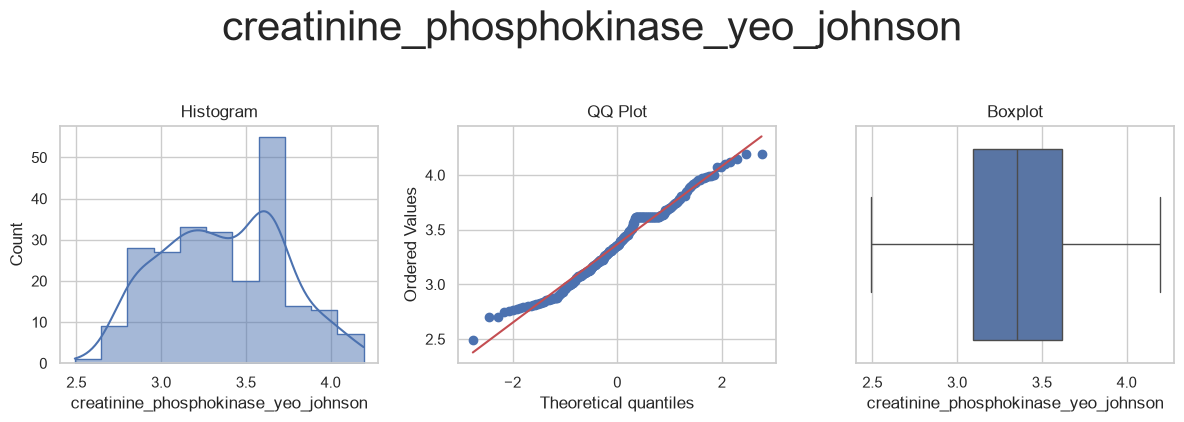



* Variable Analyzed: ejection_fraction
* Applied transformation: ['ejection_fraction_log_e', 'ejection_fraction_log_10', 'ejection_fraction_reciprocal', 'ejection_fraction_power', 'ejection_fraction_box_cox', 'ejection_fraction_yeo_johnson'] 



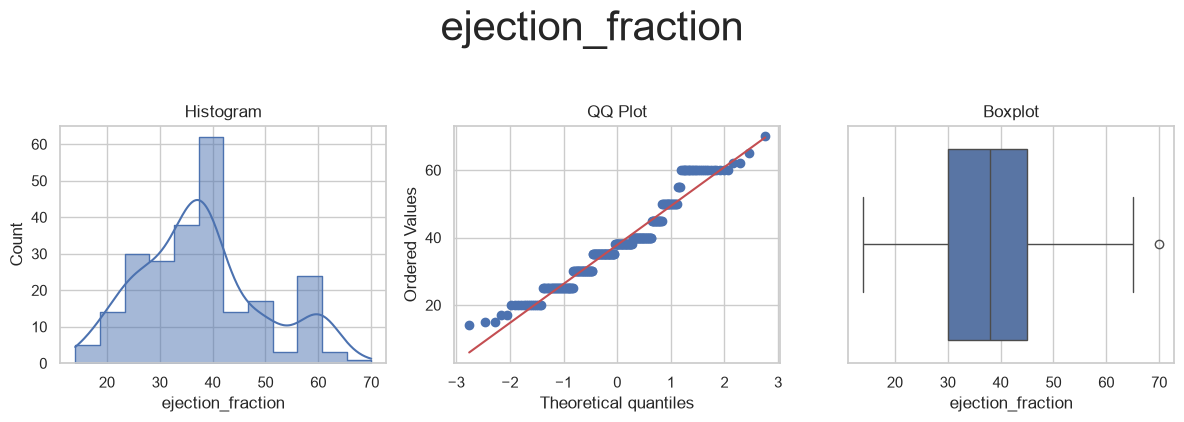

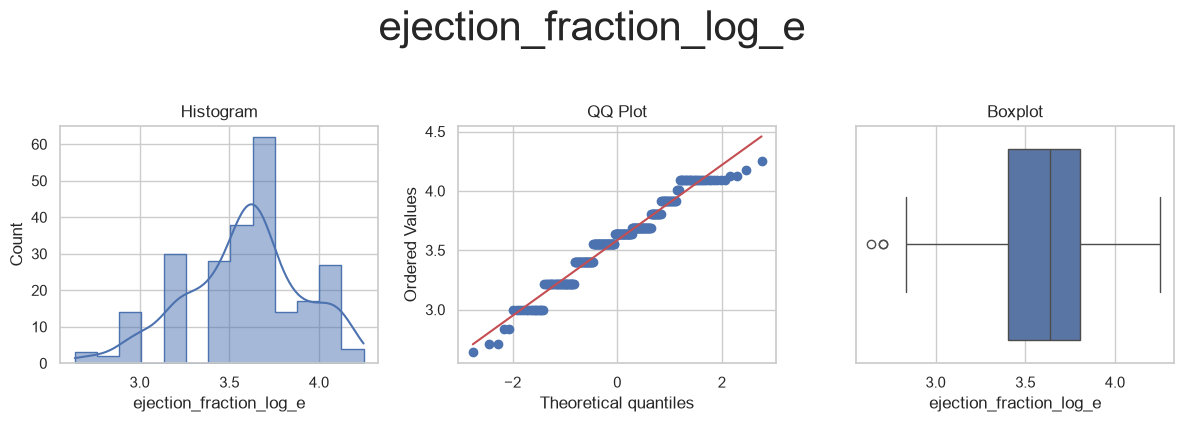

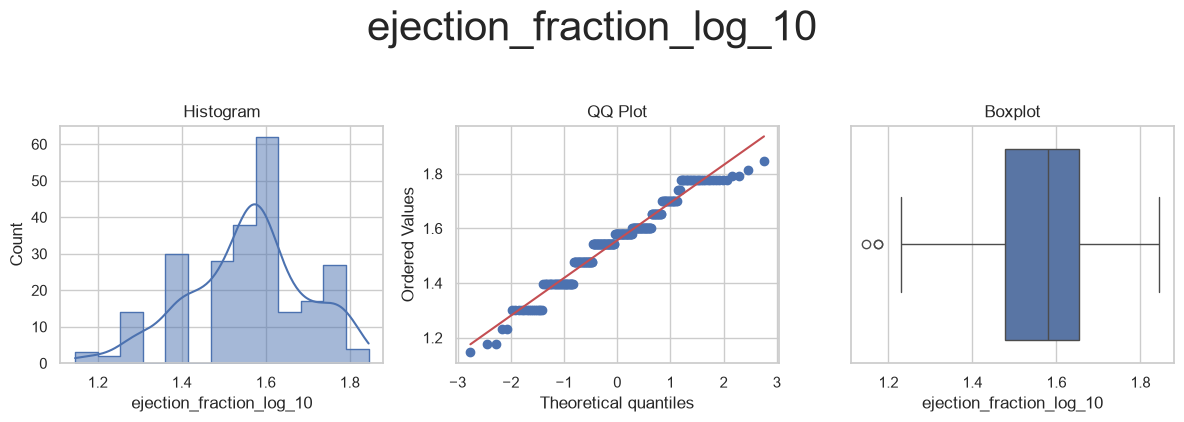

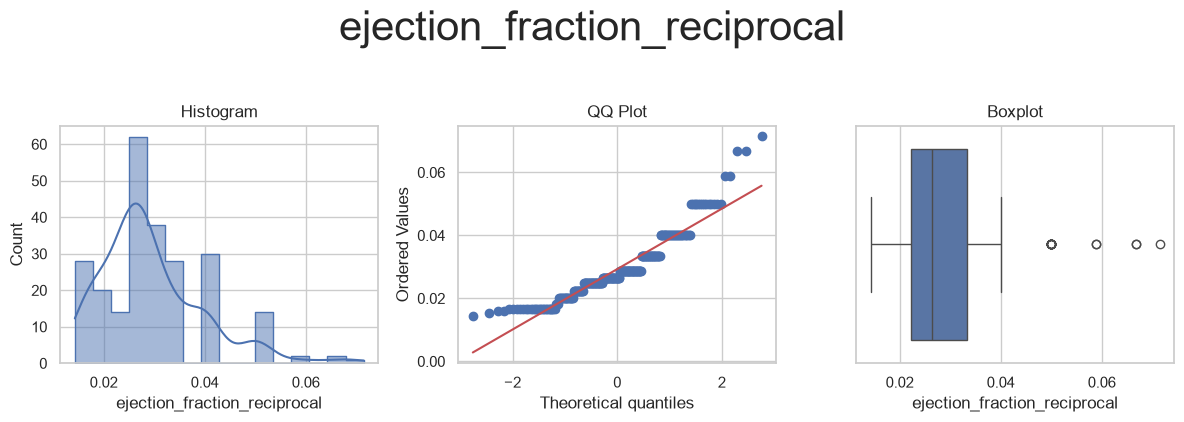

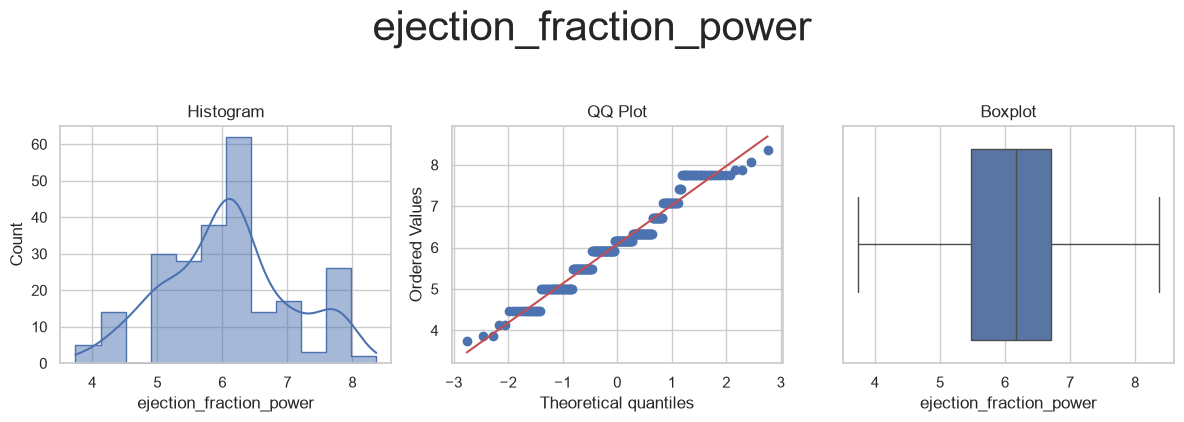

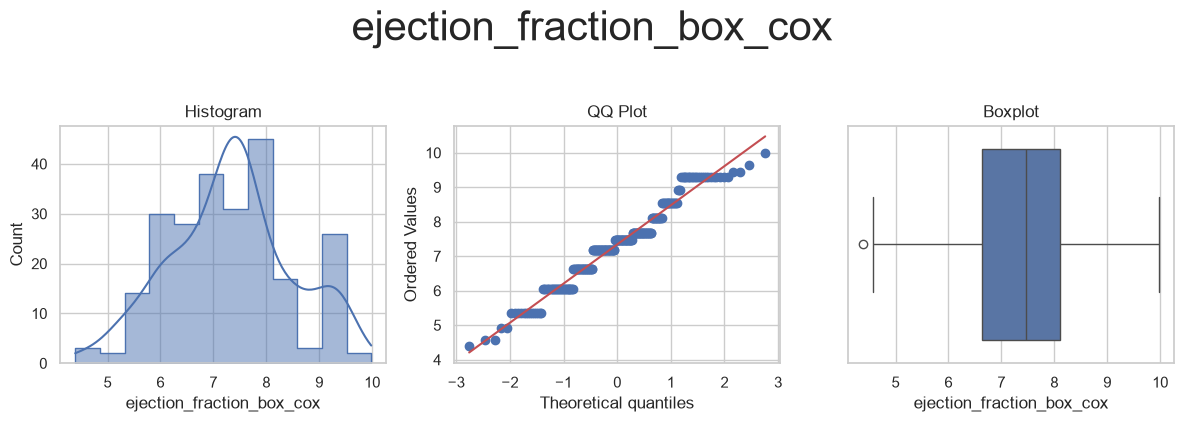

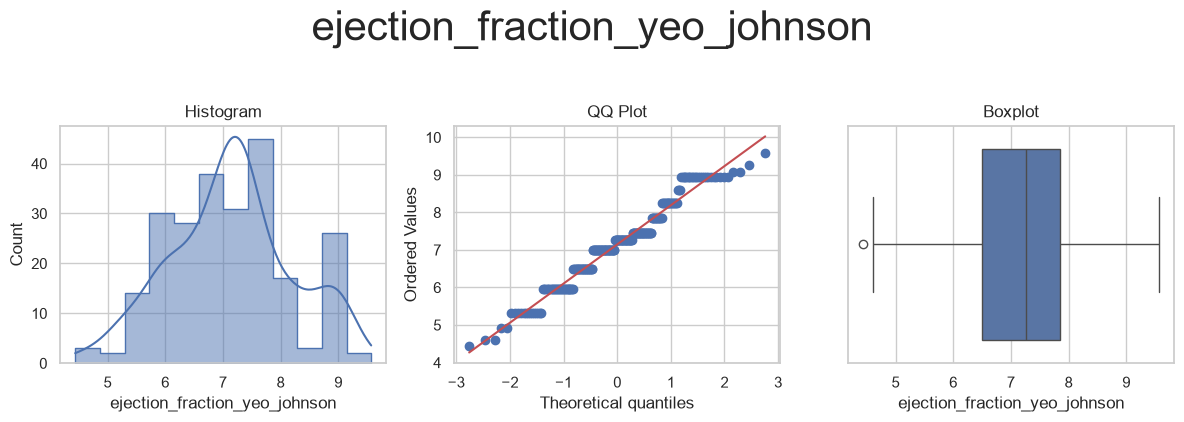



* Variable Analyzed: platelets
* Applied transformation: ['platelets_log_e', 'platelets_log_10', 'platelets_reciprocal', 'platelets_power', 'platelets_box_cox', 'platelets_yeo_johnson'] 



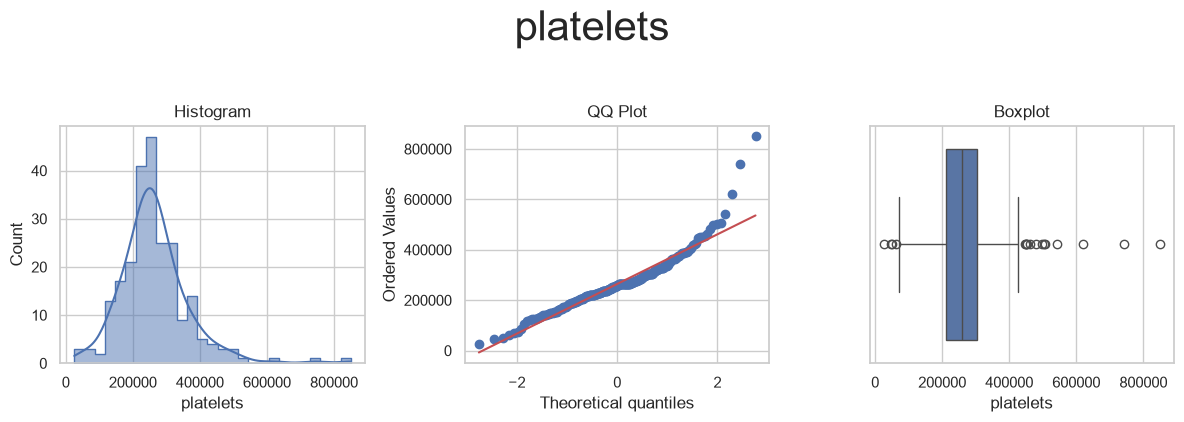

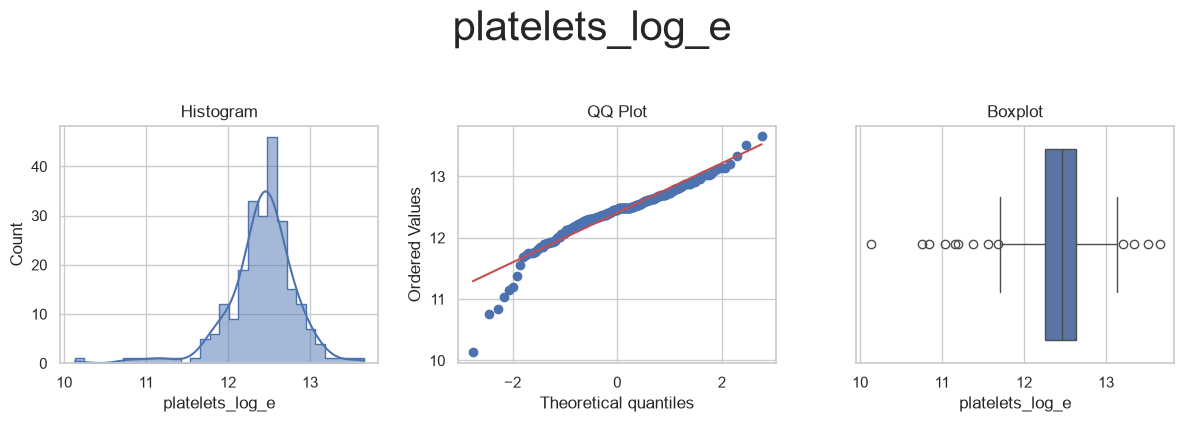

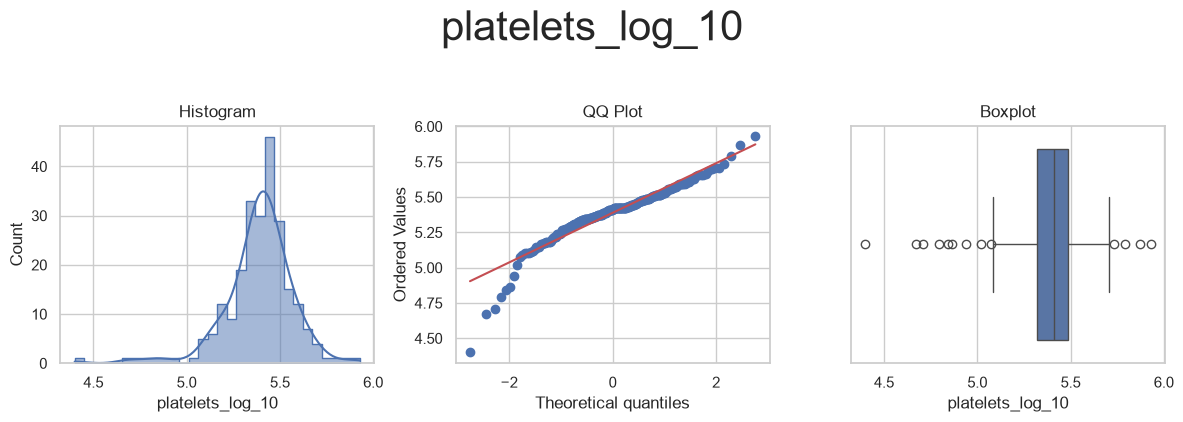

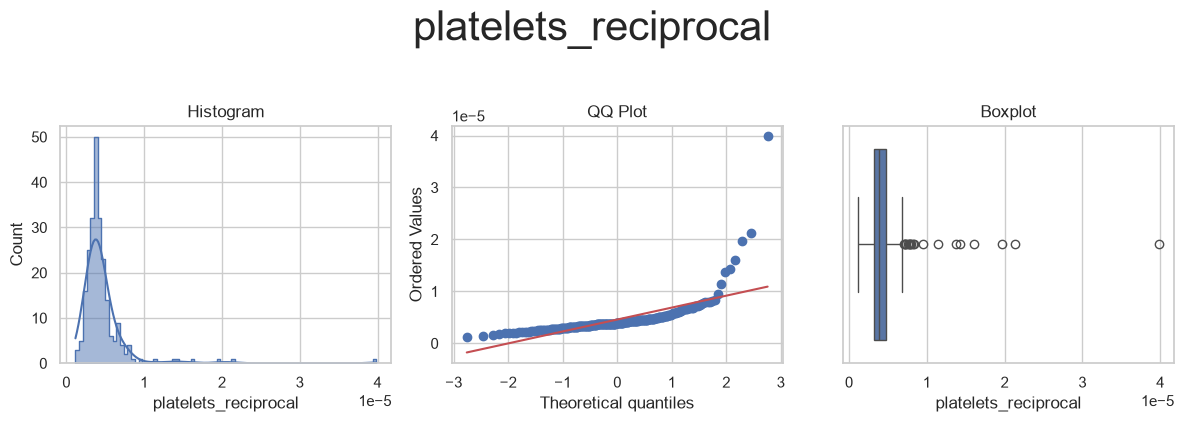

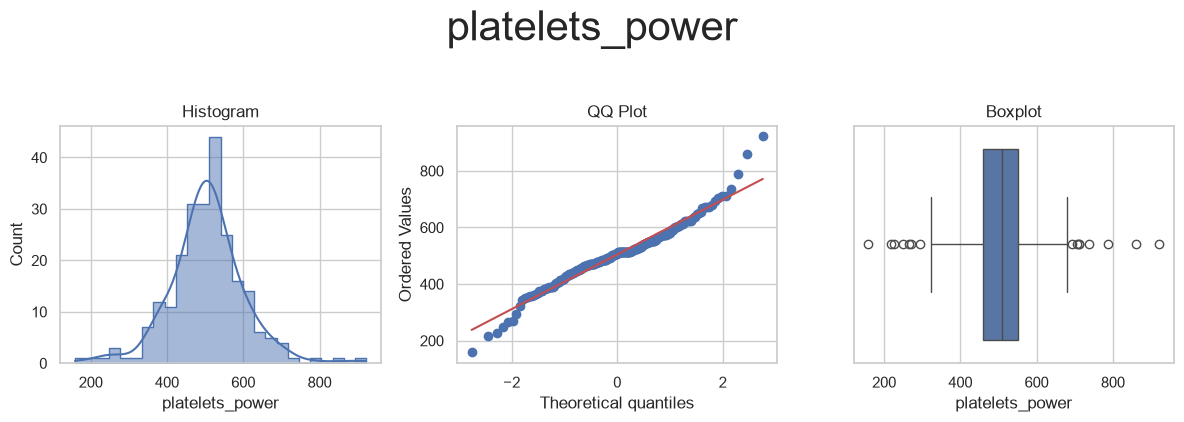

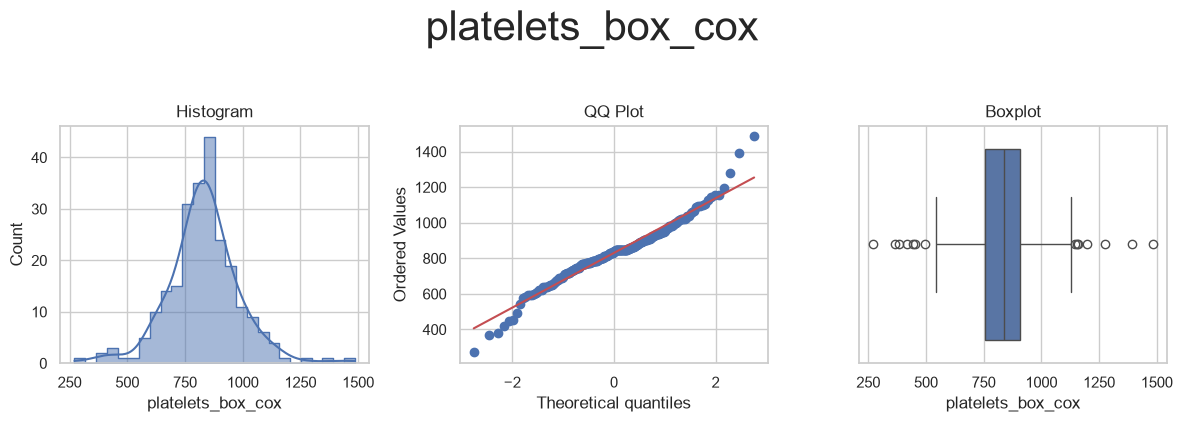

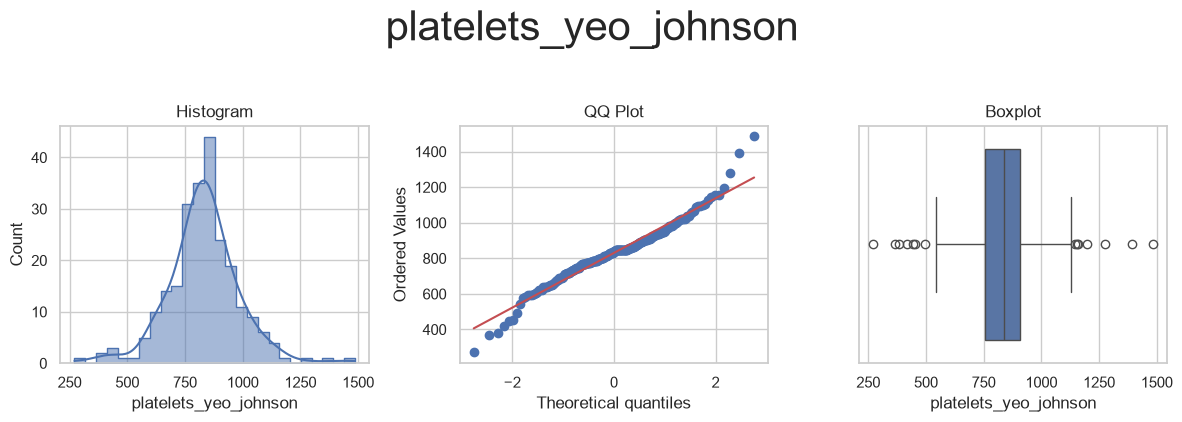



* Variable Analyzed: serum_creatinine
* Applied transformation: ['serum_creatinine_log_e', 'serum_creatinine_log_10', 'serum_creatinine_reciprocal', 'serum_creatinine_power', 'serum_creatinine_box_cox', 'serum_creatinine_yeo_johnson'] 



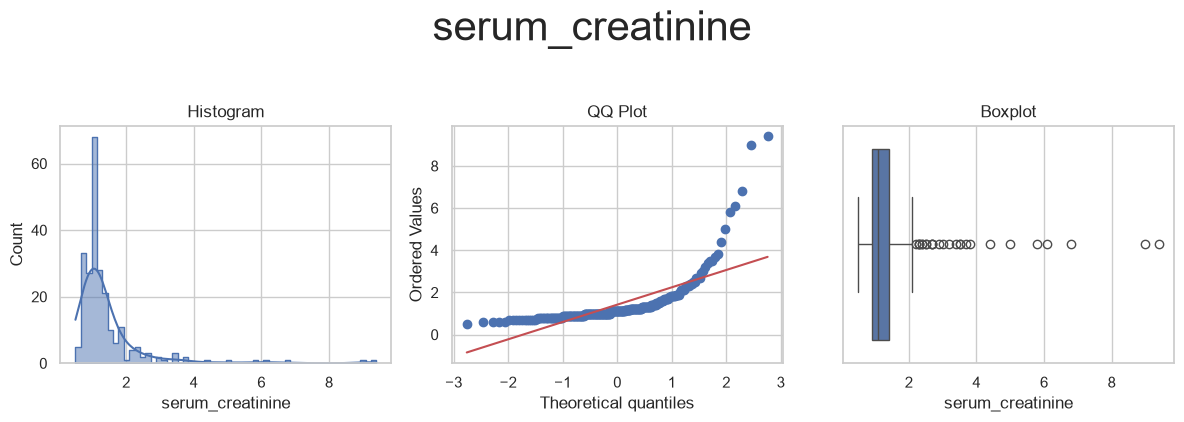

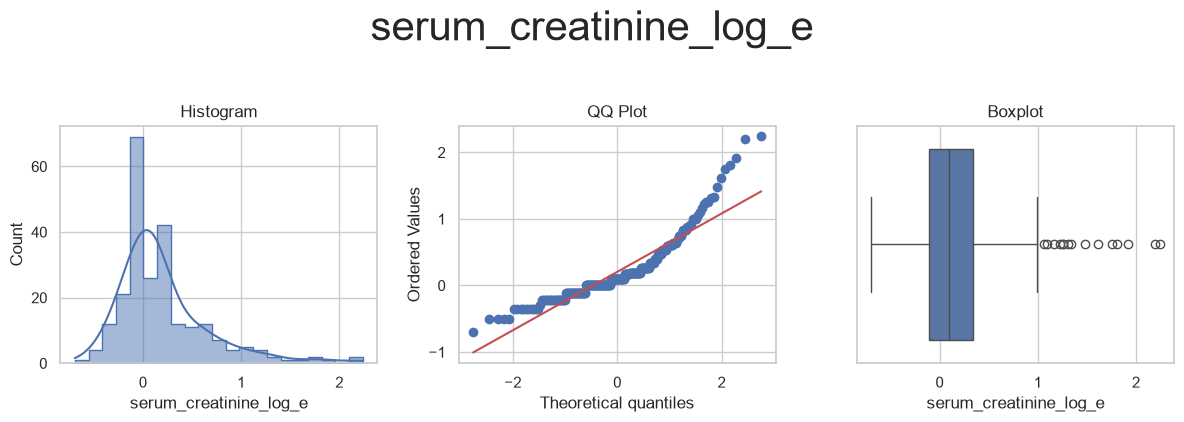

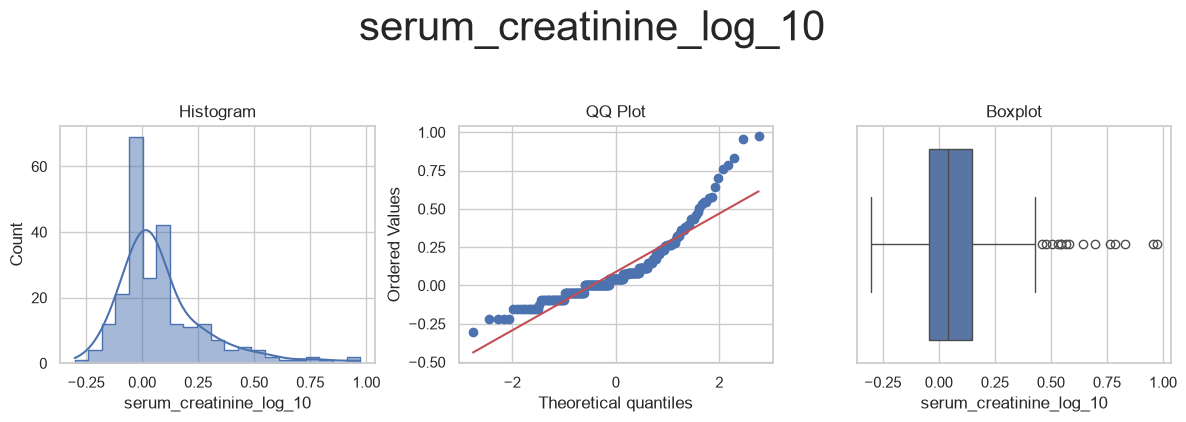

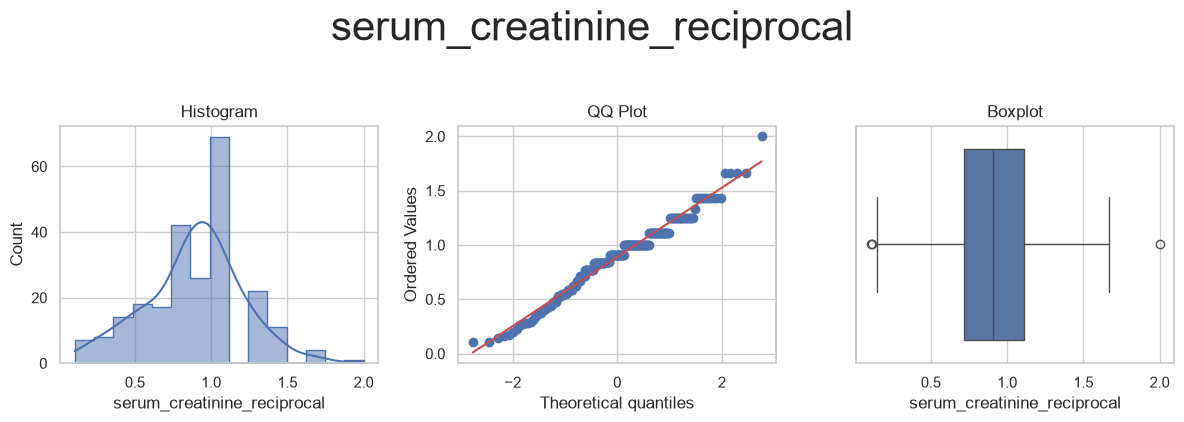

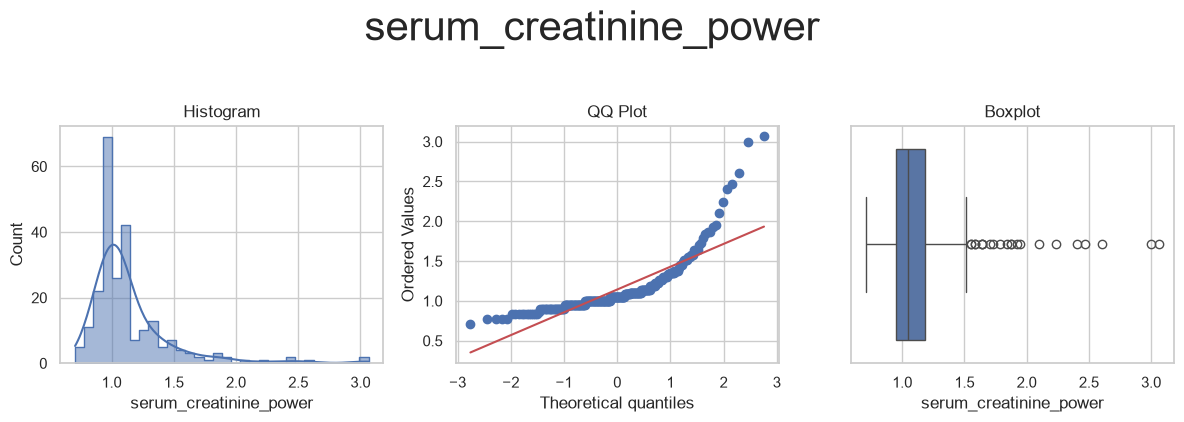

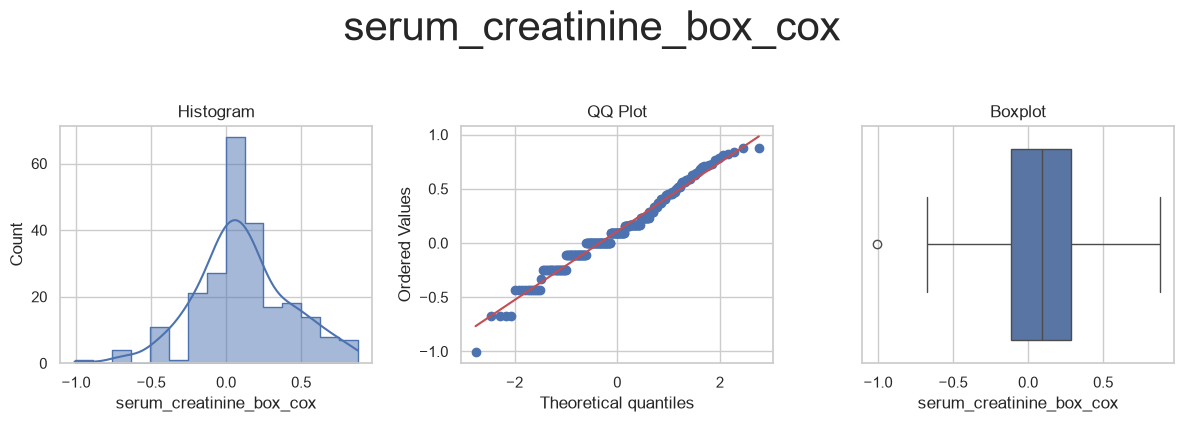

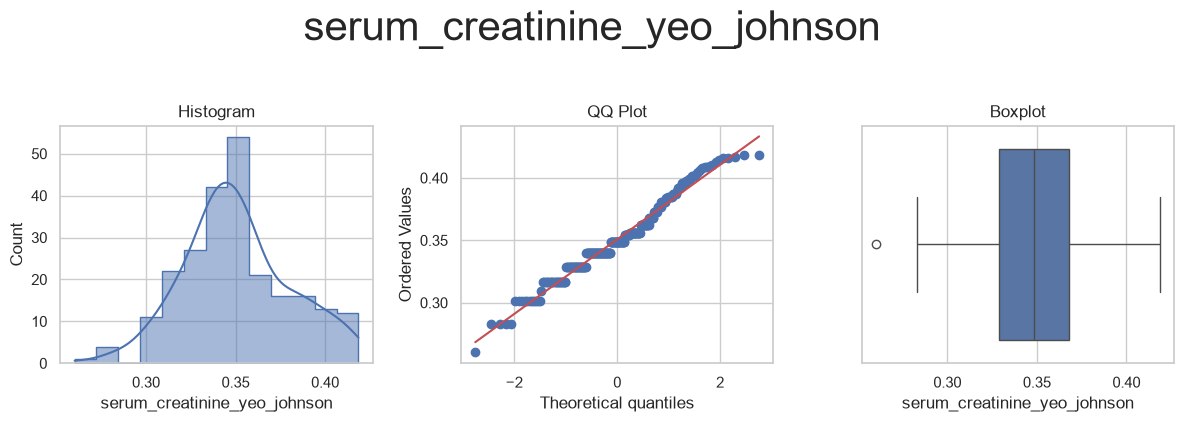



* Variable Analyzed: serum_sodium
* Applied transformation: ['serum_sodium_log_e', 'serum_sodium_log_10', 'serum_sodium_reciprocal', 'serum_sodium_power', 'serum_sodium_box_cox', 'serum_sodium_yeo_johnson'] 



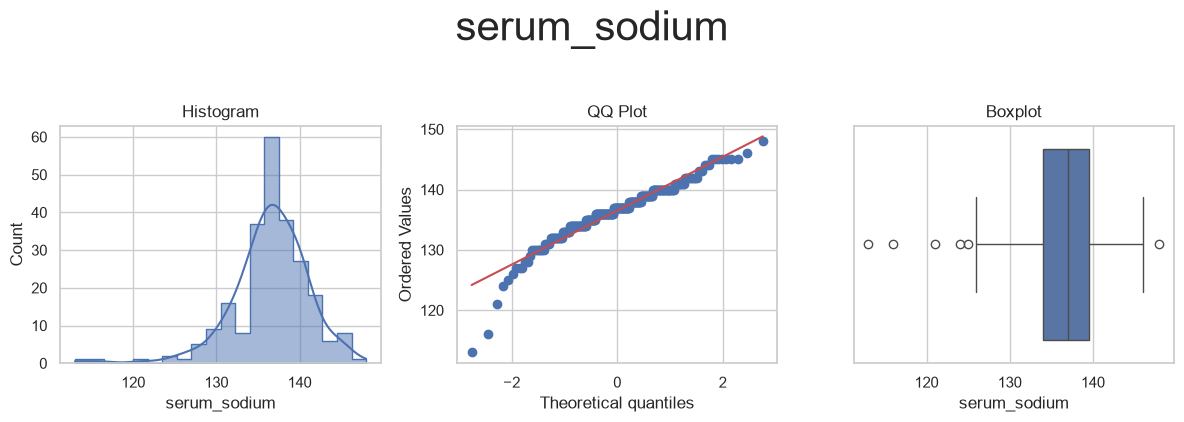

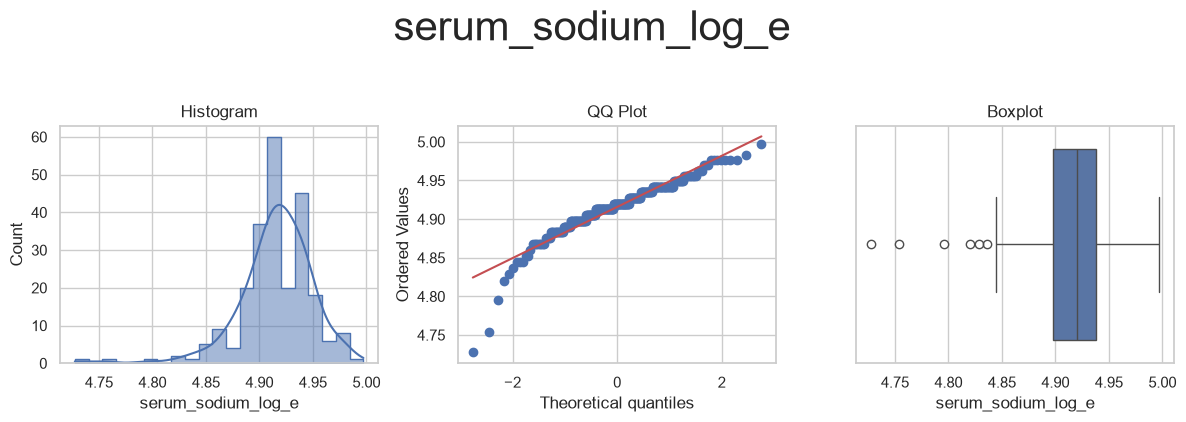

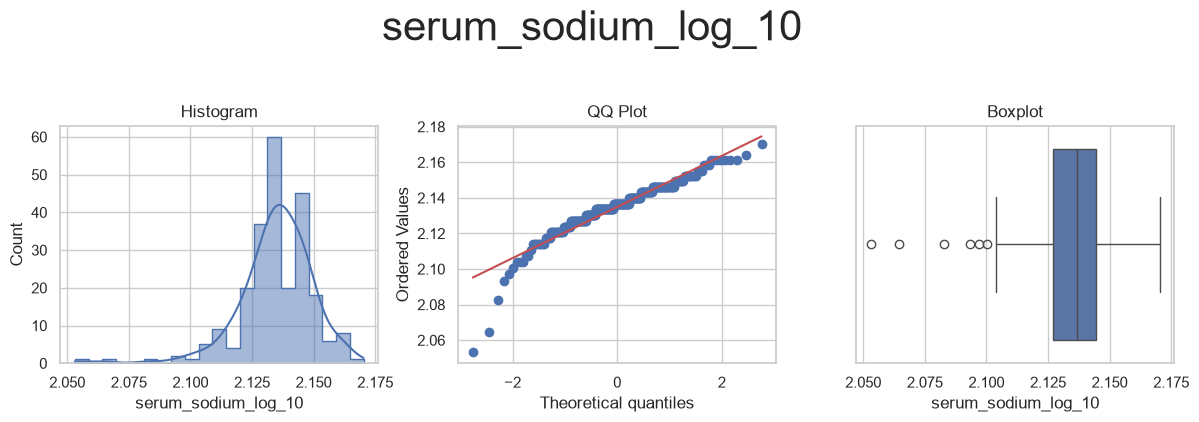

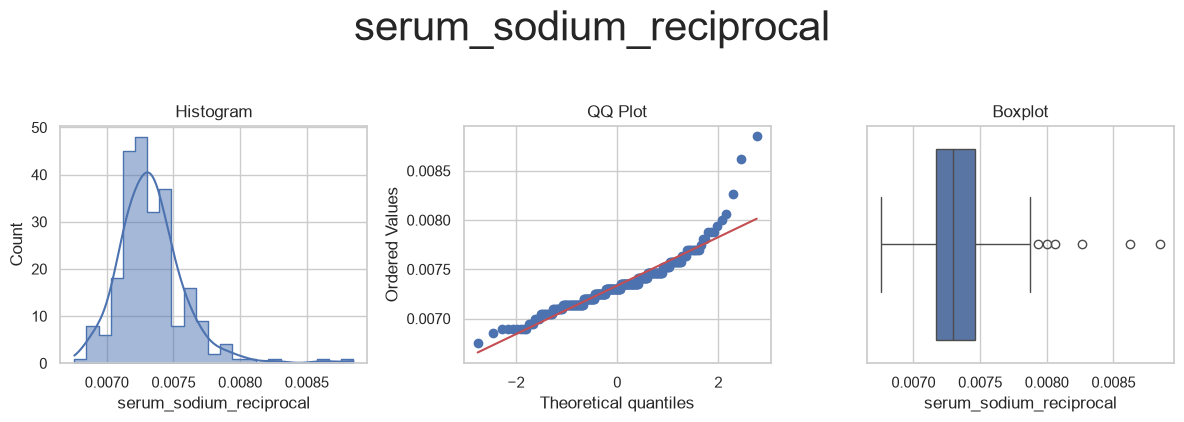

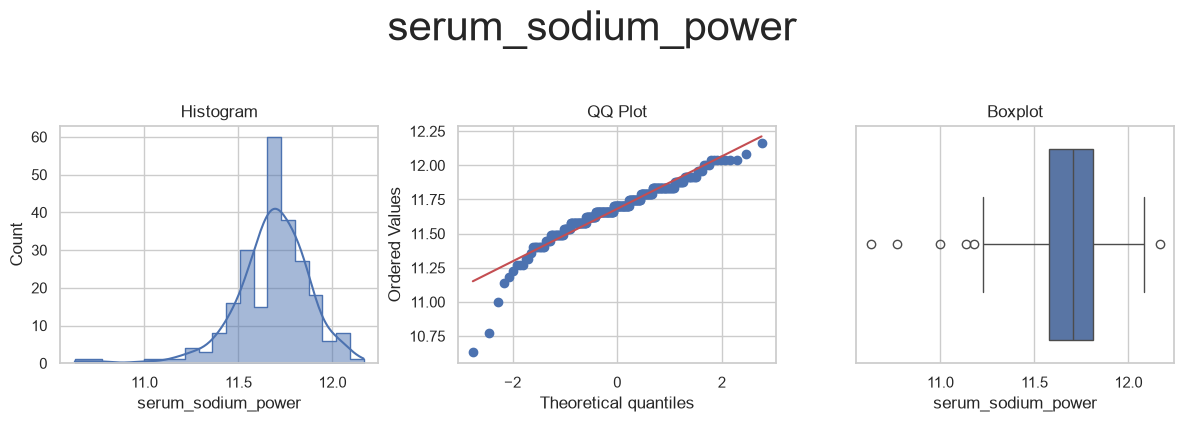

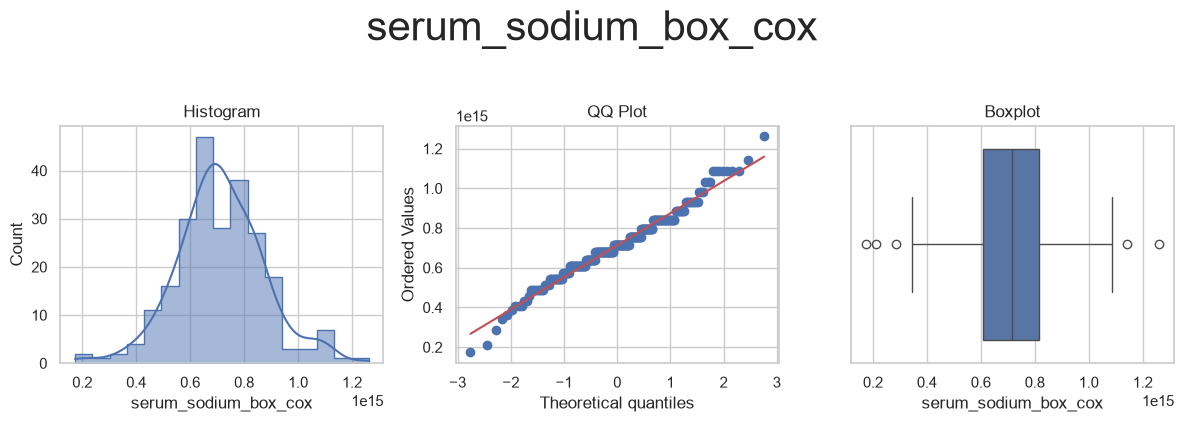

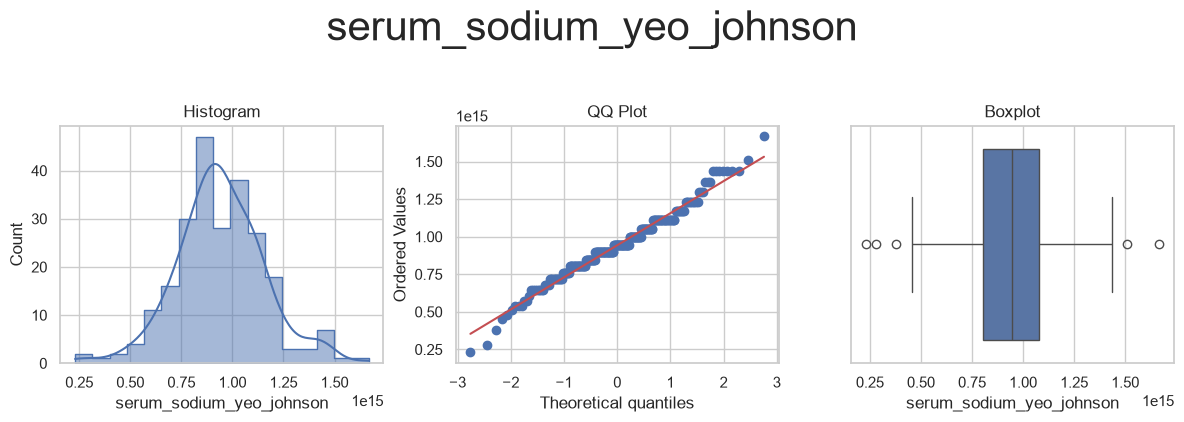



* Variable Analyzed: anaemia
* Applied transformation: ['anaemia_power', 'anaemia_yeo_johnson'] 



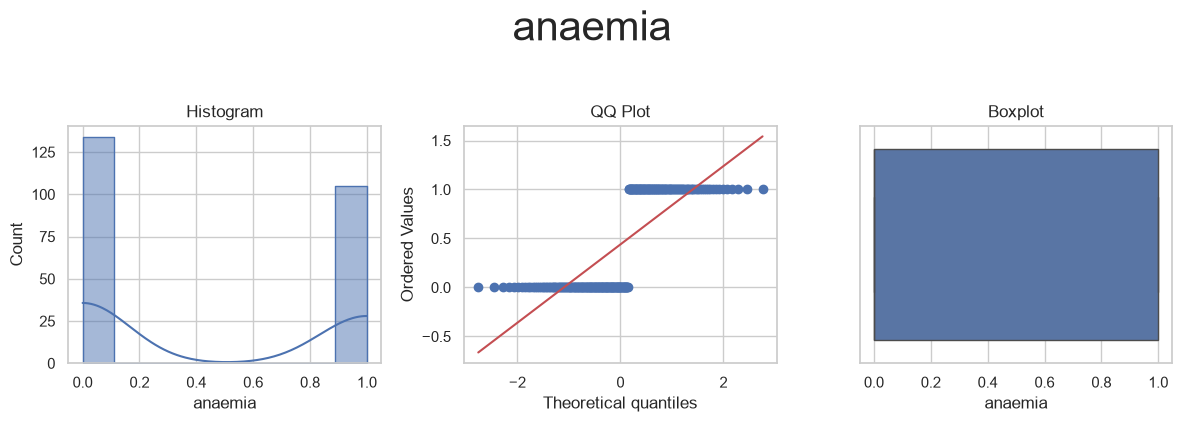

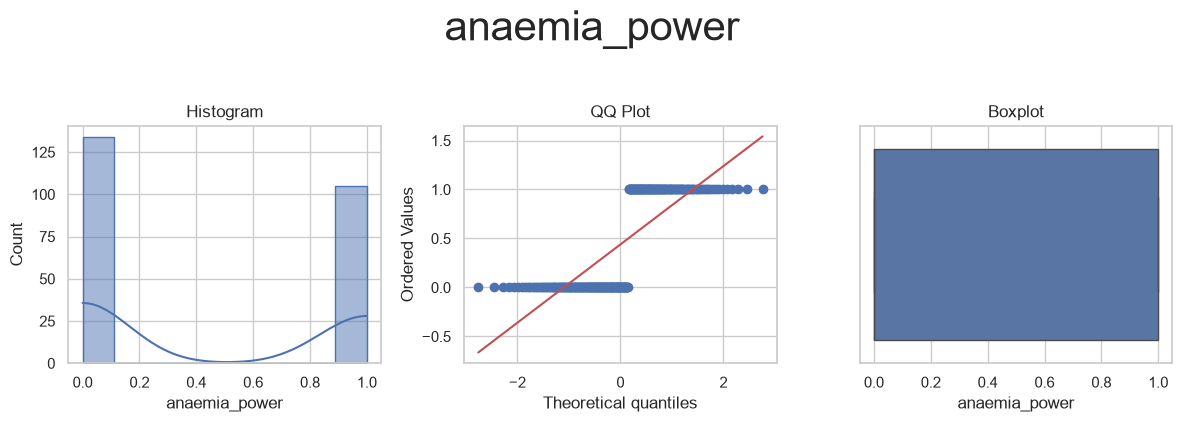

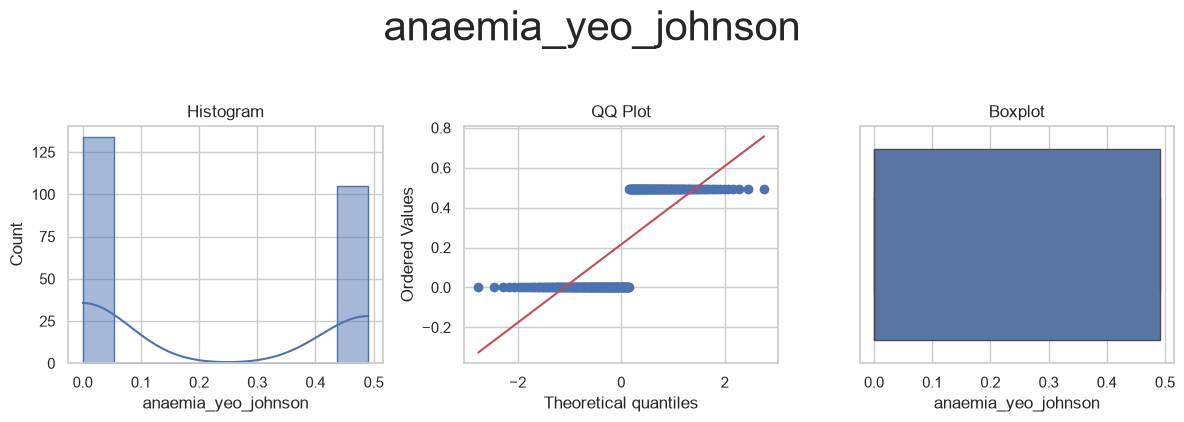



* Variable Analyzed: diabetes
* Applied transformation: ['diabetes_power', 'diabetes_yeo_johnson'] 



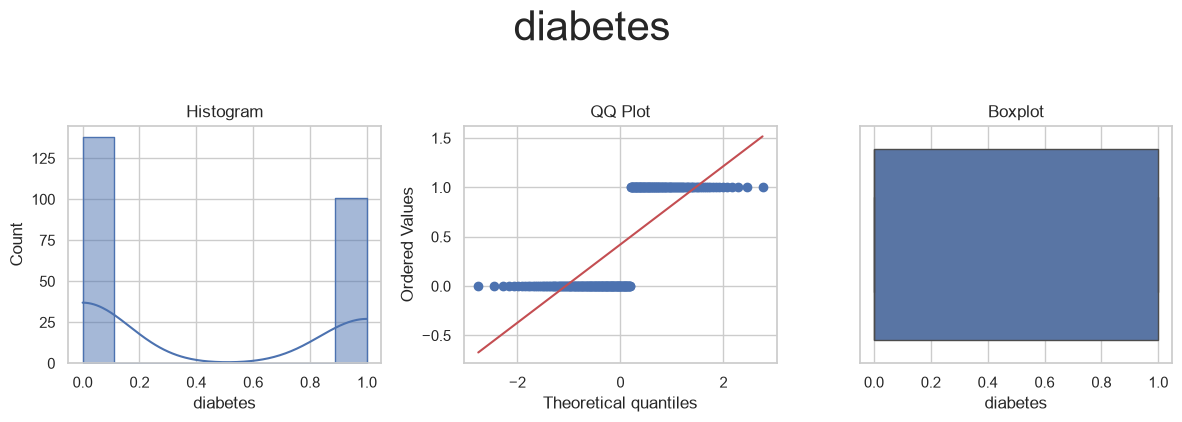

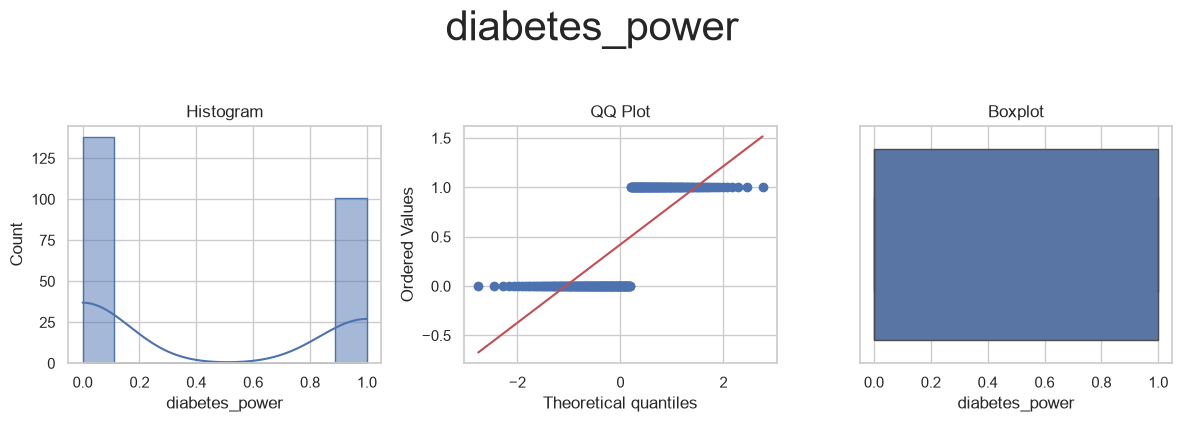

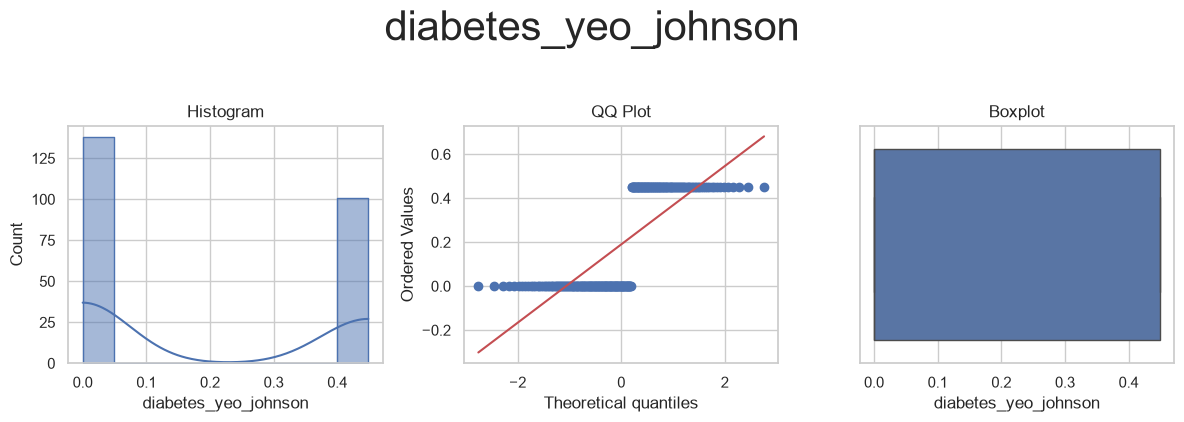



* Variable Analyzed: high_blood_pressure
* Applied transformation: ['high_blood_pressure_power', 'high_blood_pressure_yeo_johnson'] 



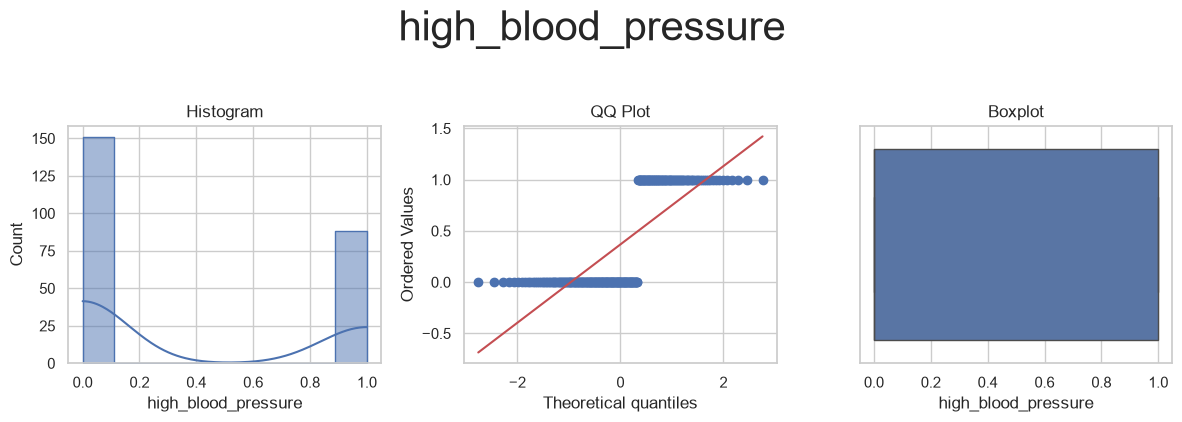

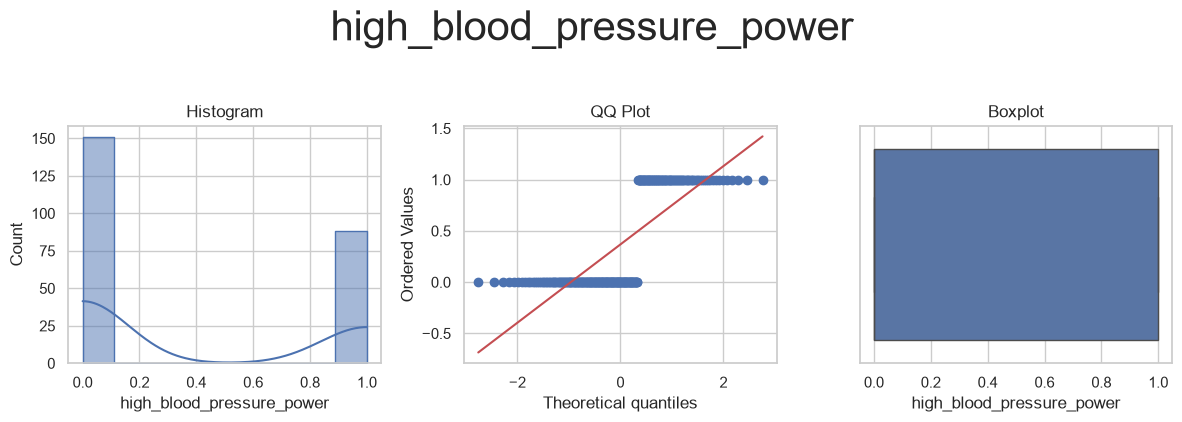

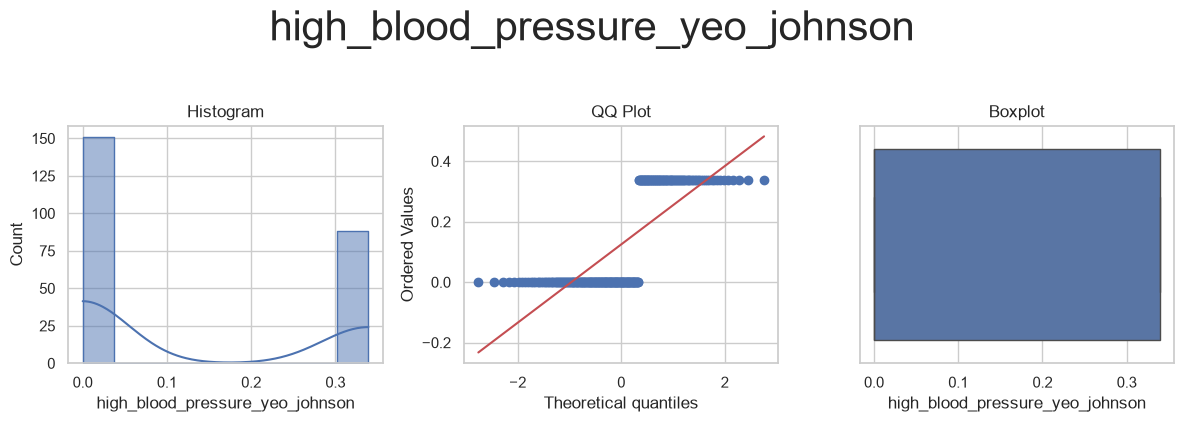



* Variable Analyzed: sex
* Applied transformation: ['sex_power', 'sex_yeo_johnson'] 



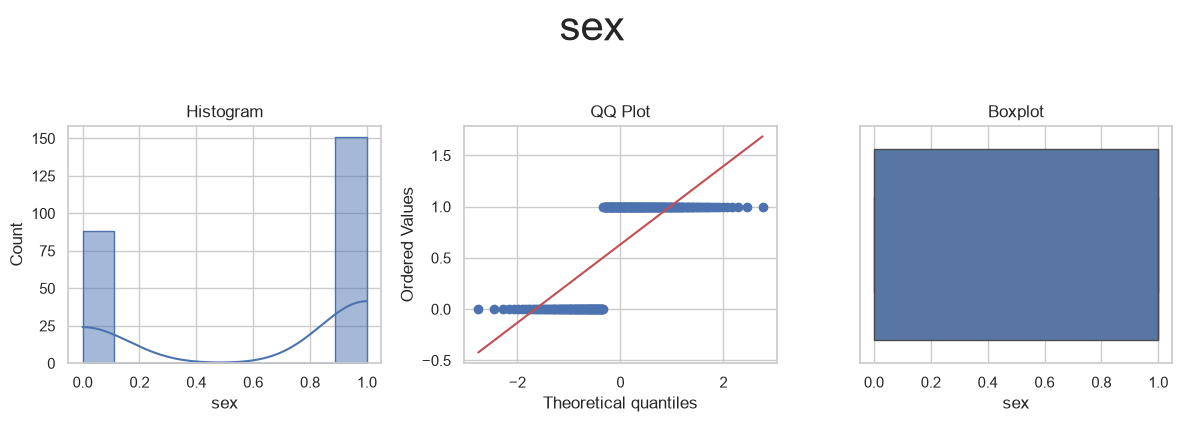

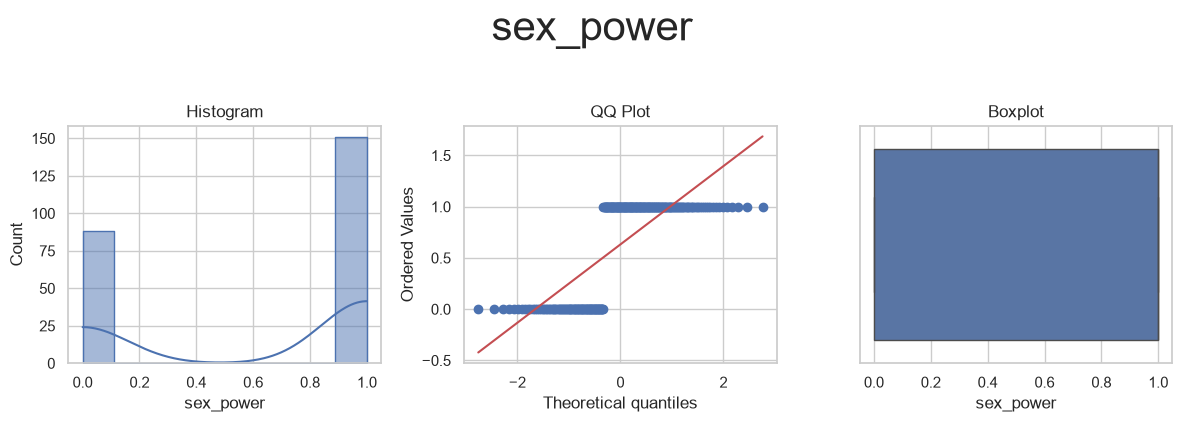

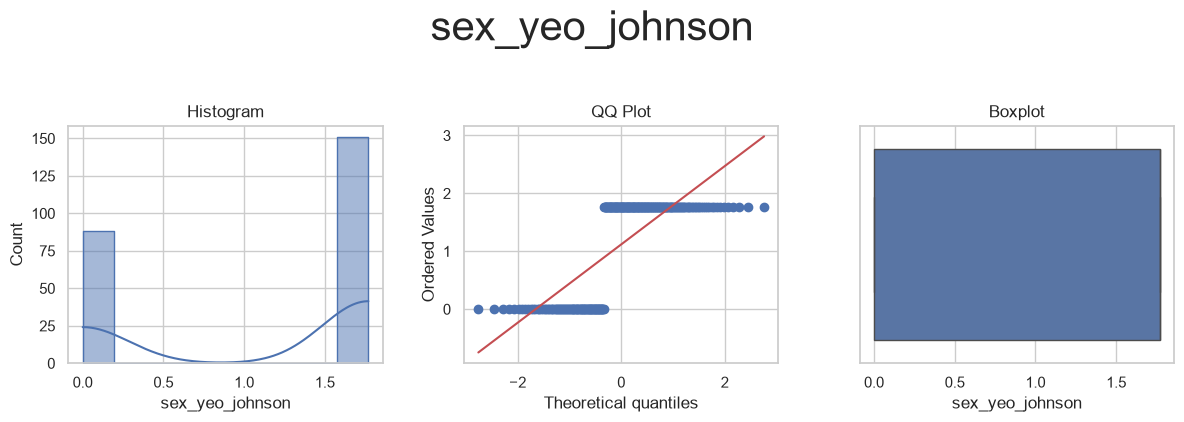



* Variable Analyzed: smoking
* Applied transformation: ['smoking_power', 'smoking_yeo_johnson'] 



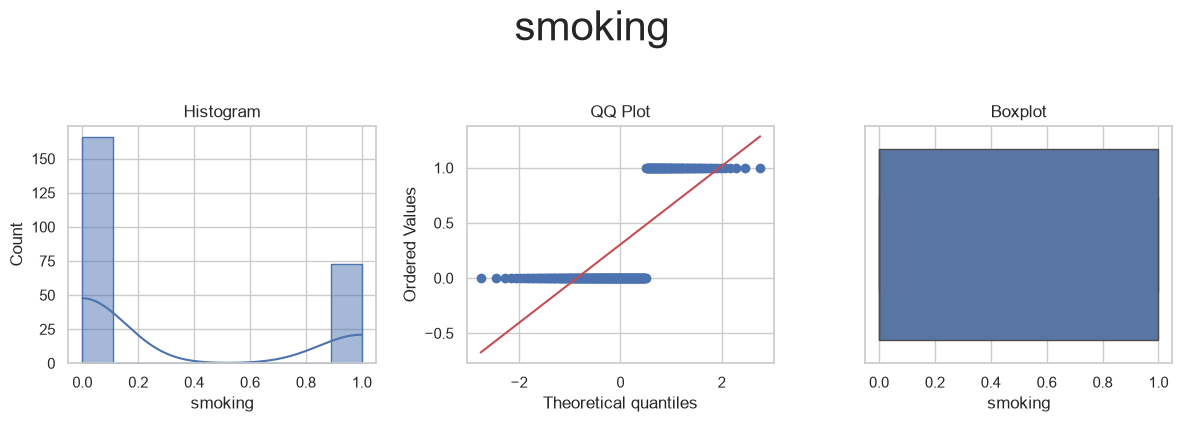

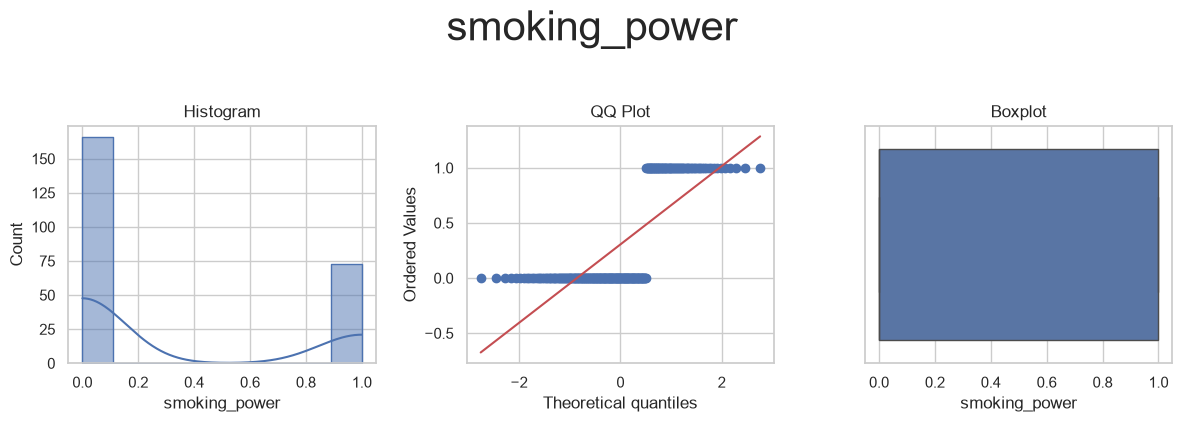

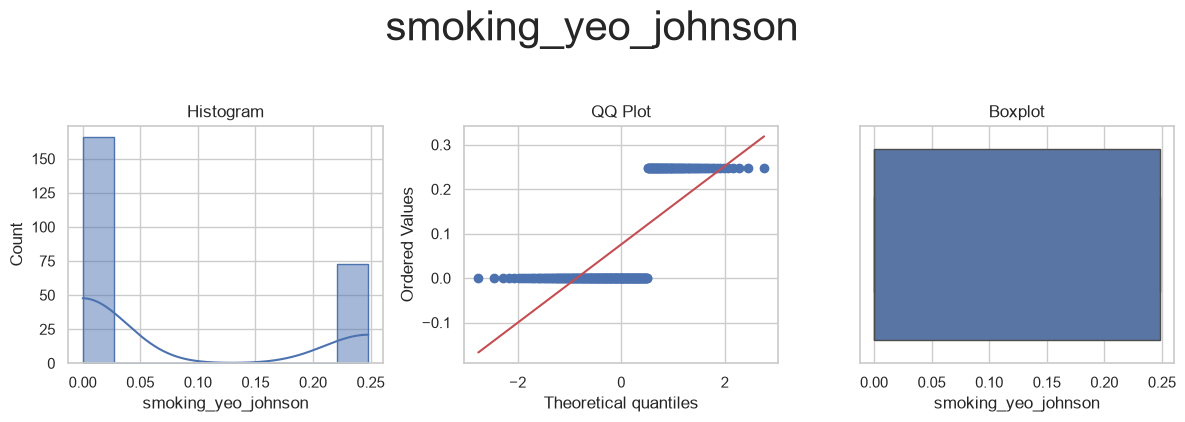

In [28]:
df_engineering = FeatureEngineeringAnalysis(df=df_engineering, analysis_type='numerical')

* For each variable, write your conclusion on how the transformation(s) look(s) to be effective
  * For all variables - it didn't improve the boxplot distribution or qq plot


* Step 4 - Apply the selected transformation to the Train and Test set

In [29]:
# we are not applying any numerical transformation to the data
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path(r"C:\python_projects\Predictive_analysis")

TrainSet = pd.read_csv(
    PROJECT_ROOT / "outputs" / "datasets" / "split" / "TrainSet.csv"
)

print("TrainSet shape:", TrainSet.shape)
print("Columns:", TrainSet.columns.tolist())

display(TrainSet.head())

TrainSet shape: (239, 12)
Columns: ['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'DEATH_EVENT']


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,DEATH_EVENT
0,50.0,0,582,0,62,1,147000.0,0.8,140,1,1,0
1,75.0,1,246,0,15,0,127000.0,1.2,137,1,0,1
2,50.0,1,168,0,38,1,276000.0,1.1,137,1,0,1
3,65.0,0,395,1,25,0,265000.0,1.2,136,1,1,1
4,40.0,0,244,0,45,1,275000.0,0.9,140,0,0,0


### SmartCorrelatedSelection Variables

* Step 1: Select variable(s)

In [30]:
# for this transformer, you don't need to select variables, since you need all variables for this transformer

* Step 2: Create a separate DataFrame, with your variable(s)

In [31]:
df_engineering = TrainSet.copy()
df_engineering.head(3)

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,DEATH_EVENT
0,50.0,0,582,0,62,1,147000.0,0.8,140,1,1,0
1,75.0,1,246,0,15,0,127000.0,1.2,137,1,0,1
2,50.0,1,168,0,38,1,276000.0,1.1,137,1,0,1


* Step 3: Create engineered variables(s) applying the transformation(s)

In [32]:
from feature_engine.selection import SmartCorrelatedSelection
corr_sel = SmartCorrelatedSelection(variables=None, method="spearman", threshold=0.6, selection_method="variance")

corr_sel.fit_transform(df_engineering)
corr_sel.correlated_feature_sets_

[]

In [33]:
corr_sel.features_to_drop_

[]

---

# So what is the conclusion? :)


The list below shows the transformations needed for feature engineering.
  * You will add these steps to the ML Pipeline


Feature Engineering Transformers
  * Ordinal categorical encoding: `['anaemia', 'diabets', sex', 'smoking','high_blood_pressure', `
  * Numerical features: `[' age',
    'ejection_fraction',
    'platelets',
    'serum_creatinine',
    'serum_sodium', 'creatinine_phosphokinase']`
  

* Well done! Clear the outputs, and move on to the following notebook.

In [34]:
X_cluster = TrainSet.drop(
    columns=["DEATH_EVENT", "time", "Clusters"],
    errors="ignore"
)

print("X_cluster shape:", X_cluster.shape)
display(X_cluster.head())

X_cluster shape: (239, 11)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking
0,50.0,0,582,0,62,1,147000.0,0.8,140,1,1
1,75.0,1,246,0,15,0,127000.0,1.2,137,1,0
2,50.0,1,168,0,38,1,276000.0,1.1,137,1,0
3,65.0,0,395,1,25,0,265000.0,1.2,136,1,1
4,40.0,0,244,0,45,1,275000.0,0.9,140,0,0


In [35]:
import joblib

MODEL_PATH = (
    PROJECT_ROOT
    / "outputs"
    / "ml_pipeline"
    / "cluster_analysis"
    / "v1"
    / "cluster_pipeline.pkl"
)

pipeline_cluster = joblib.load(MODEL_PATH)

print(pipeline_cluster)

Pipeline(steps=[('scaler', StandardScaler()),
                ('PCA', PCA(n_components=6, random_state=0)),
                ('model', KMeans(n_clusters=6, n_init=10, random_state=0))])


In [36]:
if hasattr(pipeline_cluster, "feature_names_in_"):
    expected_features = pipeline_cluster.feature_names_in_.tolist()
    X_cluster = X_cluster[expected_features]

cluster_labels = pipeline_cluster.predict(X_cluster)

df_cluster_vs_df_reduced = pd.DataFrame({
    "Clusters": cluster_labels,
    "DEATH_EVENT": TrainSet["DEATH_EVENT"].to_numpy()
})

display(df_cluster_vs_df_reduced.head())

,Clusters,DEATH_EVENT
0,5,0
1,1,1
2,5,1
3,4,1
4,2,0


In [37]:
import pandas as pd
import plotly.express as px

def cluster_distribution_per_variable(df, target):

    # Count patients by cluster and outcome
    df_bar_plot = (
        df.groupby(["Clusters", target])
        .size()
        .reset_index(name="Count")
    )

    # Convert to categorical labels
    df_bar_plot[target] = df_bar_plot[target].astype(str)
    df_bar_plot["Clusters"] = df_bar_plot["Clusters"].astype(str)

    # Create grouped bar chart
    fig = px.bar(
        df_bar_plot,
        x="Clusters",
        y="Count",
        color=target,
        barmode="group",
        title=f"Distribution of {target} Across Clusters",
        labels={
            "Count": "Number of Patients",
            "Clusters": "Cluster",
            target: "Death Event"
        }
    )

    fig.update_layout(
        xaxis_title="Cluster",
        yaxis_title="Number of Patients"
    )

    fig.show()

In [38]:
cluster_distribution_per_variable(
    df=df_cluster_vs_df_reduced,
    target="DEATH_EVENT"
)

In [39]:
import sys
import nbformat

print("Python:", sys.executable)
print("nbformat version:", nbformat.__version__)

Python: c:\python_projects\Predictive_analysis\venv\Scripts\python.exe
nbformat version: 5.11.1


In [40]:
cluster_summary = (
    df_cluster_vs_df_reduced
    .groupby("Clusters")["DEATH_EVENT"]
    .agg(
        Patients="count",
        Death_Events="sum",
        Death_Event_Rate="mean"
    )
    .reset_index()
)

cluster_summary["Death_Event_Rate"] *= 100

display(cluster_summary.round(2))

,Clusters,Patients,Death_Events,Death_Event_Rate
0,0,32,13,40.62
1,1,50,25,50.00
2,2,74,17,22.97
3,3,2,2,100.00
4,4,50,11,22.00
5,5,31,9,29.03


In [41]:
import plotly.io as pio

pio.renderers.default = "notebook"

cluster_distribution_per_variable(
    df=df_cluster_vs_df_reduced,
    target="DEATH_EVENT"
)

In [42]:
import plotly.io as pio

pio.renderers.default = "browser"

cluster_distribution_per_variable(
    df=df_cluster_vs_df_reduced,
    target="DEATH_EVENT"
)

In [43]:
cluster_summary = (
    df_cluster_vs_df_reduced
    .groupby("Clusters")["DEATH_EVENT"]
    .agg(
        Patients="count",
        Death_Events="sum",
        Death_Event_Rate="mean"
    )
    .reset_index()
)

cluster_summary["Death_Event_Rate"] *= 100

display(cluster_summary.round(2))

,Clusters,Patients,Death_Events,Death_Event_Rate
0,0,32,13,40.62
1,1,50,25,50.00
2,2,74,17,22.97
3,3,2,2,100.00
4,4,50,11,22.00
5,5,31,9,29.03


In [44]:
fig = px.bar(
    cluster_summary,
    x="Clusters",
    y="Death_Event_Rate",
    text="Death_Event_Rate",
    title="Death Event Rate by Cluster",
    labels={
        "Death_Event_Rate": "Death Event Rate (%)",
        "Clusters": "Cluster"
    }
)

fig.update_traces(texttemplate="%{text:.1f}%", textposition="outside")
fig.update_yaxes(range=[0, 100])

fig.show()

In [45]:
import pandas as pd
import plotly.express as px
from pathlib import Path

PROJECT_ROOT = Path(r"C:\python_projects\Predictive_analysis")
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def cluster_distribution_per_variable(df, target):

    df_bar_plot = (
        df.groupby(["Clusters", target])
        .size()
        .reset_index(name="Count")
    )

    df_bar_plot[target] = df_bar_plot[target].astype(str)
    df_bar_plot["Clusters"] = df_bar_plot["Clusters"].astype(str)

    fig = px.bar(
        df_bar_plot,
        x="Clusters",
        y="Count",
        color=target,
        barmode="group",
        title=f"Distribution of {target} Across Clusters",
        labels={
            "Count": "Number of Patients",
            "Clusters": "Cluster",
            target: "Death Event"
        }
    )

    fig.update_layout(
        width=950,
        height=550,
        template="plotly_white"
    )

    # Save interactive HTML figure
    html_path = FIGURES_DIR / "cluster_death_event_distribution.html"
    fig.write_html(str(html_path))

    # Save PNG image
    png_path = FIGURES_DIR / "cluster_death_event_distribution.png"
    fig.write_image(str(png_path), scale=2)

    print(f"HTML saved: {html_path}")
    print(f"PNG saved: {png_path}")

    fig.show()